In [36]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train_data_df = pd.read_csv('train.csv')
test_data_df = pd.read_csv('train.csv')

In [4]:
train_data_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
test_data_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
train_data_df.shape

(891, 12)

In [8]:
train_data_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [11]:
train_data_df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [12]:
train_data_df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [13]:
train_data_df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

**Check Null**

In [15]:
train_data_df.info()

train_data_df.isnull().sum().sort_values(ascending=False)


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

**Analysis** As we can see cabin has 687 missing out of 891, almost 77%. age has 177 missing, apprx. 20%. and Embarked only 2 missing. Let's handle these missing values first.

In [16]:
##Age we will use Sex, Parch, PClass and Title to group and fill median age for the missing values


import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# Use only passengers with known ages
# Keep the original train_data_df unchanged
age_df = train_data_df.dropna(subset=["Age"]).copy()

# Family indicator
age_df["HasParch"] = (age_df["Parch"] > 0).astype(int)

# Extract titles from names
age_df["Title"] = age_df["Name"].str.extract(
    r",\s*([^.]+)\."
)[0].str.strip()

# Standardize similar titles
age_df["Title"] = age_df["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

# Group uncommon titles
common = ["Mr", "Mrs", "Miss", "Master"]

age_df["Title"] = age_df["Title"].where(
    age_df["Title"].isin(common), "Rare"
)

# Define age-imputation methods
methods = {
    "A: Sex + Pclass":
        ["Sex", "Pclass"],

    "B: + HasParch":
        ["Sex", "Pclass", "HasParch"],

    "C: + Title":
        ["Sex", "Pclass", "HasParch", "Title"]
}

# 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate each imputation method
for method, columns in methods.items():

    scores = []

    for train_idx, val_idx in kf.split(age_df):

        tr = age_df.iloc[train_idx]
        val = age_df.iloc[val_idx]

        # Calculate median ages using training fold only
        medians = tr.groupby(columns)["Age"].median()

        # Fallback for unseen combinations
        fallback = tr.groupby(
            ["Sex", "Pclass"]
        )["Age"].median()

        overall = tr["Age"].median()

        # Predict missing ages using group medians
        def predict_age(row):

            key = tuple(row[c] for c in columns)

            estimate = medians.get(key, np.nan)

            if pd.isna(estimate):
                estimate = fallback.get(
                    (row["Sex"], row["Pclass"]),
                    overall
                )

            return estimate

        # Predict ages in validation fold
        predictions = val.apply(
            predict_age,
            axis=1
        )

        # Calculate Mean Absolute Error
        mae = mean_absolute_error(
            val["Age"],
            predictions
        )

        scores.append(mae)

    # Average MAE across 5 folds
    print(f"{method}: {np.mean(scores):.3f} years")




A: Sex + Pclass: 10.396 years
B: + HasParch: 10.233 years
C: + Title: 8.512 years


**Age Missing Value Imputation – Methodology and Results**

To determine the most effective approach for handling missing values in the Age feature, we evaluated three median-based imputation strategies using 5-fold cross-validation on 714 passengers with known ages. Model A estimated missing ages using Sex and Pclass, achieving a Mean Absolute Error (MAE) of 10.396 years. Model B incorporated an additional family relationship indicator (HasParch), reducing the MAE slightly to 10.233 years. Model C further incorporated passenger titles (Mr, Mrs, Miss, Master, and Rare) extracted from the Name column, achieving the lowest MAE of 8.512 years, representing an 18.1% reduction in estimation error compared with Model A. These results demonstrate that feature engineering, particularly extracting passenger titles, significantly improves age estimation. Based on these findings, Model C was selected as the preferred imputation strategy for handling missing ages in both the training and test datasets. An additional binary feature, AgeMissing, will be created to distinguish originally missing ages from observed values. The impact of this imputation strategy on survival prediction will be evaluated during subsequent model training and validation.

**Impute missing Age values**

In [17]:
# 1. Create copies of the original datasets
train_clean_df = train_data_df.copy()
test_clean_df = test_data_df.copy()

# 2. Create additional features
for df in [train_clean_df, test_clean_df]:

    # Indicator: 1 = Age was missing, 0 = known
    df["AgeMissing"] = df["Age"].isna().astype(int)

    # Family indicator
    df["HasParch"] = (df["Parch"] > 0).astype(int)

    # Extract passenger title
    df["Title"] = df["Name"].str.extract(
        r",\s*([^.]+)\."
    )[0].str.strip()

    # Standardize titles
    df["Title"] = df["Title"].replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })

    common = ["Mr", "Mrs", "Miss", "Master"]

    df["Title"] = df["Title"].where(
        df["Title"].isin(common), "Rare"
    )

# 3. Define Model C grouping variables
group_cols = ["Sex", "Pclass", "HasParch", "Title"]

# Calculate medians using TRAINING DATA ONLY
age_medians = train_clean_df.groupby(
    group_cols
)["Age"].median()

# Fallback medians for unseen combinations
fallback_medians = train_clean_df.groupby(
    ["Sex", "Pclass"]
)["Age"].median()

overall_median = train_clean_df["Age"].median()

# 4. Define age imputation function
def impute_age(row):

    # Preserve known ages
    if pd.notna(row["Age"]):
        return row["Age"]

    key = tuple(row[col] for col in group_cols)

    estimated_age = age_medians.get(key, np.nan)

    # Fallback if combination has no known ages
    if pd.isna(estimated_age):
        estimated_age = fallback_medians.get(
            (row["Sex"], row["Pclass"]),
            overall_median
        )

    return estimated_age

# 5. Fill missing ages in both datasets
for df in [train_clean_df, test_clean_df]:
    df["Age"] = df.apply(impute_age, axis=1)

# 6. Verify results
print("Training missing ages:",
      train_clean_df["Age"].isna().sum())

print("Test missing ages:",
      test_clean_df["Age"].isna().sum())

print("\nTraining imputed ages:",
      train_clean_df.loc[
          train_clean_df["AgeMissing"] == 1,
          ["PassengerId", "Sex", "Pclass",
           "HasParch", "Title", "Age"]
      ].head(10))


Training missing ages: 0
Test missing ages: 0

Training imputed ages:     PassengerId     Sex  Pclass  HasParch Title   Age
5             6    male       3         0    Mr  26.0
17           18    male       2         0    Mr  30.0
19           20  female       3         0   Mrs  31.0
26           27    male       3         0    Mr  26.0
28           29  female       3         0  Miss  21.0
29           30    male       3         0    Mr  26.0
31           32  female       1         0   Mrs  36.5
32           33  female       3         0  Miss  21.0
36           37    male       3         0    Mr  26.0
42           43    male       3         0    Mr  26.0


In [18]:
train_clean_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeMissing,HasParch,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,0,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,0,Mr


In [25]:
train_clean_df['Age'].isnull().value_counts()

Age
False    891
Name: count, dtype: int64

In [27]:
##Cabin

# Extract deck from cabin number
for df in [train_clean_df, test_clean_df]:

    df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

    df["CabinKnown"] = df["Cabin"].notna().astype(int)

# Examine distribution
print(train_clean_df["Deck"].value_counts())


Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64


In [28]:
#Embarked — Fill missing values with the mode

# Calculate mode from training data only
embarked_mode = train_clean_df["Embarked"].mode()[0]

print("Most frequent port:", embarked_mode)

# Fill missing values
train_clean_df["Embarked"] = (
    train_clean_df["Embarked"].fillna(embarked_mode)
)

test_clean_df["Embarked"] = (
    test_clean_df["Embarked"].fillna(embarked_mode)
)


Most frequent port: S


In [29]:
#3. Fare — Median by passenger class

# Calculate fare medians from training data
fare_medians = train_clean_df.groupby(
    "Pclass"
)["Fare"].median()

print("Median fare by class:")
print(fare_medians)

# Fill missing fares using passenger class
overall_fare = train_clean_df["Fare"].median()

for df in [train_clean_df, test_clean_df]:
    df["Fare"] = df["Fare"].fillna(
        df["Pclass"].map(fare_medians)
    ).fillna(overall_fare)


Median fare by class:
Pclass
1    60.2875
2    14.2500
3     8.0500
Name: Fare, dtype: float64


In [30]:
#Verify data

# Check missing values in both datasets
print("TRAINING DATA - Missing Values")
print(
    train_clean_df.isnull().sum().sort_values(
        ascending=False
    )
)

print("\nTEST DATA - Missing Values")
print(
    test_clean_df.isnull().sum().sort_values(
        ascending=False
    )
)

# Verify selected modeling features
features = [
    "Age", "Fare", "Embarked",
    "Deck", "CabinKnown",
    "AgeMissing", "HasParch", "Title"
]

print("\nMissing values in selected features:")
print(train_clean_df[features].isnull().sum())
print(test_clean_df[features].isnull().sum())


TRAINING DATA - Missing Values
Cabin          687
PassengerId      0
Survived         0
Name             0
Pclass           0
Age              0
SibSp            0
Parch            0
Sex              0
Ticket           0
Fare             0
Embarked         0
AgeMissing       0
HasParch         0
Title            0
Deck             0
CabinKnown       0
dtype: int64

TEST DATA - Missing Values
Cabin          687
PassengerId      0
Survived         0
Name             0
Pclass           0
Age              0
SibSp            0
Parch            0
Sex              0
Ticket           0
Fare             0
Embarked         0
AgeMissing       0
HasParch         0
Title            0
Deck             0
CabinKnown       0
dtype: int64

Missing values in selected features:
Age           0
Fare          0
Embarked      0
Deck          0
CabinKnown    0
AgeMissing    0
HasParch      0
Title         0
dtype: int64
Age           0
Fare          0
Embarked      0
Deck          0
CabinKnown    0
AgeMissing

**Missing Data Treatment – Cabin, Embarked, and Fare**

Following the imputation of missing Age values, we addressed the remaining missing data in the Cabin, Embarked, and Fare features using appropriate preprocessing techniques. The Cabin variable contained 687 missing values (77.1%) in the training dataset and 327 (78.2%) in the test dataset. Rather than dropping this feature, we applied feature engineering to extract the deck letter into a new categorical variable (Deck), assigning "Unknown" to missing entries. We also created a binary indicator (CabinKnown) to capture whether cabin information was originally available. For Embarked, which contained only two missing values in the training dataset, we applied mode imputation, replacing missing entries with "S" (Southampton), the most frequently occurring embarkation port. For Fare, which contained one missing value in the test dataset, we applied group-based median imputation using the passenger's ticket class (Pclass) to account for differences in fare distributions. All imputation statistics were calculated exclusively from the training dataset to prevent information leakage from the test data. Following these transformations, the selected modeling features contained no remaining missing values, while the original Cabin column was preserved for reference. These preprocessing steps retained all passenger records, preserved potentially predictive information, and prepared the datasets for exploratory data analysis and subsequent machine learning modeling.

In [31]:
##Drop Cabin and keep enginered features

# Drop original Cabin column from both datasets
train_clean_df.drop(columns=["Cabin"], inplace=True)
test_clean_df.drop(columns=["Cabin"], inplace=True)

# Verify the engineered features
print(train_clean_df[["Deck", "CabinKnown"]].head(10))

# Check remaining missing values
print("\nTraining missing values:")
print(train_clean_df.isnull().sum())

print("\nTest missing values:")
print(test_clean_df.isnull().sum())


      Deck  CabinKnown
0  Unknown           0
1        C           1
2  Unknown           0
3        C           1
4  Unknown           0
5  Unknown           0
6        E           1
7  Unknown           0
8  Unknown           0
9  Unknown           0

Training missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
AgeMissing     0
HasParch       0
Title          0
Deck           0
CabinKnown     0
dtype: int64

Test missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
AgeMissing     0
HasParch       0
Title          0
Deck           0
CabinKnown     0
dtype: int64


**Exploratory Data Analysis (EDA)**

We will investigate the following:

    What percentage of Titanic passengers survived?
    Did survival rates differ between men and women?
    Did passenger class affect survival?
    How did age and family relationships relate to survival?
    Did fare, embarkation port, or deck influence survival?

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


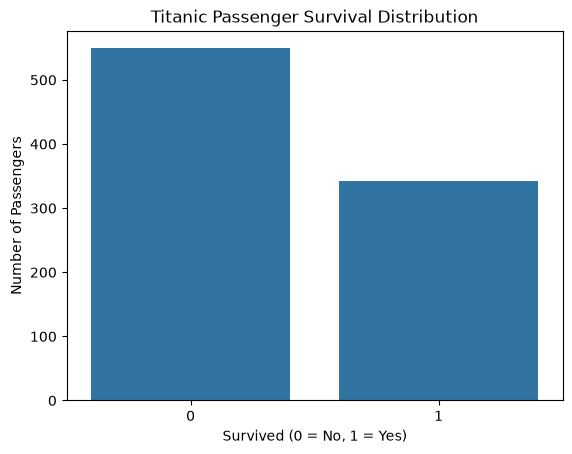

In [37]:
# Count passengers by survival outcome
survival_counts = train_clean_df["Survived"].value_counts()
survival_rates = (
    train_clean_df["Survived"].value_counts(normalize=True) * 100
)

print("Survival Counts:")
print(survival_counts)

print("\nSurvival Percentages:")
print(survival_rates.round(2))

# Visualize survival distribution
sns.countplot(
    data=train_clean_df,
    x="Survived"
)

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


**Interpretation**

Our dataset has a moderate class imbalance: approximately 62% did not survive, compared with 38% who survived.

A model that predicts everyone died would achieve 61.6% accuracy, so this gives us a baseline to beat.

In [39]:
#Analyze survival by gender and passenger class


# Survival rate by gender
gender_survival = (
    train_clean_df.groupby("Sex")["Survived"]
    .agg(["count", "sum", "mean"])
)

gender_survival["mean"] *= 100
gender_survival.columns = [
    "Passengers", "Survived", "Survival_Rate_Pct"
]

print("Survival by Gender:")
print(gender_survival.round(2))

# Survival rate by passenger class
class_survival = (
    train_clean_df.groupby("Pclass")["Survived"]
    .agg(["count", "sum", "mean"])
)

class_survival["mean"] *= 100
class_survival.columns = [
    "Passengers", "Survived", "Survival_Rate_Pct"
]

print("\nSurvival by Passenger Class:")
print(class_survival.round(2))


Survival by Gender:
        Passengers  Survived  Survival_Rate_Pct
Sex                                            
female         314       233              74.20
male           577       109              18.89

Survival by Passenger Class:
        Passengers  Survived  Survival_Rate_Pct
Pclass                                         
1              216       136              62.96
2              184        87              47.28
3              491       119              24.24


**Interpretation**

Gender and passenger class both show strong associations with survival.

Women had substantially higher survival rates than men, while first-class passengers had higher survival rates than second- and third-class passengers.

However, association doesn't necessarily mean causation. We should also investigate whether these variables interact.

Sex     female   male
Pclass               
1        96.81  36.89
2        92.11  15.74
3        50.00  13.54


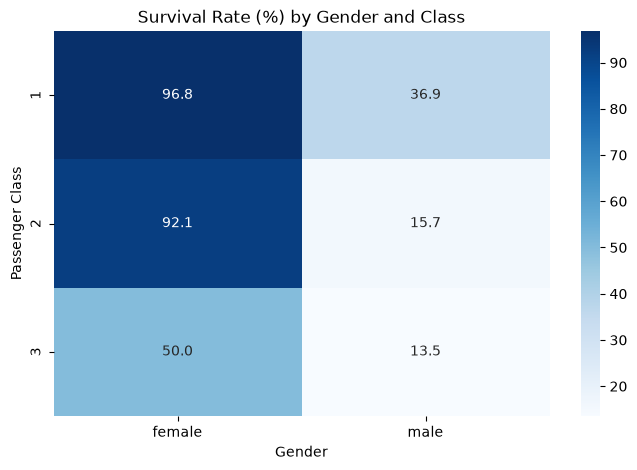

In [40]:
#Gender and passenger class combined


# Survival rates by gender and passenger class
survival_matrix = train_clean_df.pivot_table(
    values="Survived",
    index="Pclass",
    columns="Sex",
    aggfunc="mean"
) * 100

print(survival_matrix.round(2))

# Heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    survival_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Survival Rate (%) by Gender and Class")
plt.xlabel("Gender")
plt.ylabel("Passenger Class")
plt.show()


Notice something interesting: first- and second-class women had survival rates exceeding 90%, while third-class women had a survival rate of just 50%.

This suggests that gender and passenger class may interact, meaning the relationship between gender and survival differs across passenger classes.

For our eventual model, we can test whether adding an interaction feature such as Sex × Pclass improves predictive performance.

          count   mean  median    std   min   max
Survived                                         
0           549  29.64    26.0  13.20  1.00  74.0
1           342  28.17    28.0  14.21  0.42  80.0


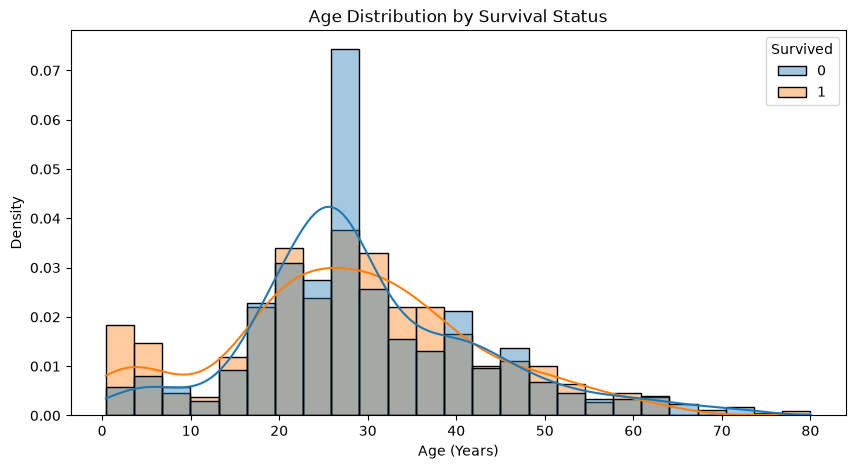

In [41]:
#Analyze survival by Age




# Summary statistics by survival outcome
age_summary = train_clean_df.groupby(
    "Survived"
)["Age"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(age_summary.round(2))

# Plot age distribution by survival outcome
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_clean_df,
    x="Age",
    hue="Survived",
    bins=25,
    kde=True,
    stat="density",
    common_norm=False,
    alpha=0.4
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age (Years)")
plt.ylabel("Density")
plt.show()


The age distribution analysis revealed relatively small differences in average age between survivors and non-survivors. Passengers who survived had a mean age of 28.17 years, compared with 29.64 years for those who did not survive. The distributions overlap substantially, suggesting that age alone is not a strong predictor of survival. However, younger children appear more frequently among survivors relative to their group size. The pronounced concentration of passengers around ages 25–30 may partly reflect our earlier median-based age imputation, which introduced repeated estimated values.


                     Passengers  Survived  SurvivalRate
AgeGroup                                               
Child (0-12)                 82        43         52.44
Teen (13-18)                 70        30         42.86
Young Adult (19-35)         493       173         35.09
Adult (36-50)               182        74         40.66
Older Adult (51-65)          56        21         37.50
Senior (65+)                  8         1         12.50


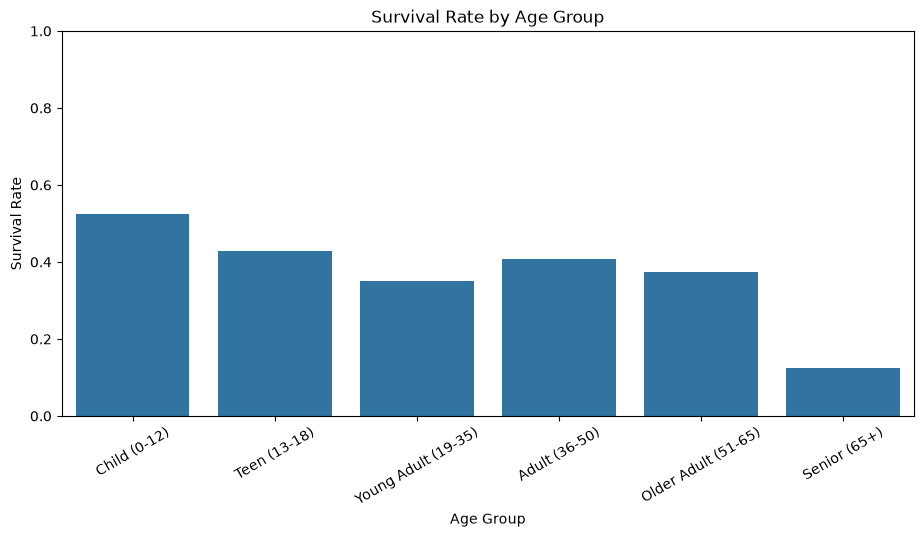

In [42]:
#Survival rates by age group


# Create age groups
age_bins = [0, 12, 18, 35, 50, 65, np.inf]

age_labels = [
    "Child (0-12)",
    "Teen (13-18)",
    "Young Adult (19-35)",
    "Adult (36-50)",
    "Older Adult (51-65)",
    "Senior (65+)"
]

train_clean_df["AgeGroup"] = pd.cut(
    train_clean_df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Calculate survival rates by age group
age_group_survival = (
    train_clean_df.groupby(
        "AgeGroup", observed=True
    )["Survived"]
    .agg(["count", "sum", "mean"])
)

age_group_survival.columns = [
    "Passengers", "Survived", "SurvivalRate"
]

age_group_survival["SurvivalRate"] *= 100

print(age_group_survival.round(2))

# Plot survival rate by age group
plt.figure(figsize=(11, 5))

sns.barplot(
    data=train_clean_df,
    x="AgeGroup",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.show()


Survival rates varied across age groups, with children aged 0–12 having the highest survival rate at 52.44%, followed by teenagers at 42.86%. Young adults aged 19–35 had a lower survival rate of 35.09%, while adults aged 36–50 had a survival rate of 40.66%. Passengers over 65 had the lowest survival rate at 12.50%, although this group contained only eight individuals. These findings suggest a nonlinear relationship between age and survival, indicating that age-based categories may provide additional predictive information. However, these results include imputed ages and should be interpreted cautiously.

            Passengers  Survived  SurvivalRate
FamilySize                                    
1                  537       163         30.35
2                  161        89         55.28
3                  102        59         57.84
4                   29        21         72.41
5                   15         3         20.00
6                   22         3         13.64
7                   12         4         33.33
8                    6         0          0.00
11                   7         0          0.00


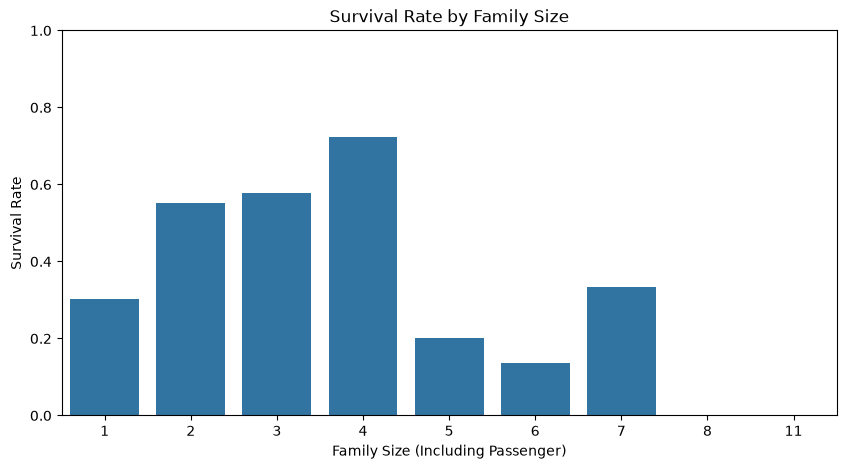

In [43]:
## family relationships and survival


# Create family size feature
# Add 1 to include the passenger
train_clean_df["FamilySize"] = (
    train_clean_df["SibSp"]
    + train_clean_df["Parch"]
    + 1
)

# Calculate survival statistics
family_survival = (
    train_clean_df.groupby("FamilySize")["Survived"]
    .agg(["count", "sum", "mean"])
)

family_survival.columns = [
    "Passengers", "Survived", "SurvivalRate"
]

family_survival["SurvivalRate"] *= 100

print(family_survival.round(2))

# Visualize
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train_clean_df,
    x="FamilySize",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size (Including Passenger)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()



**Interpretation:** 
Family size showed a meaningful association with survival probability. Passengers traveling alone had a survival rate of 30.35%, while those in families of two, three, and four had survival rates of 55.28%, 57.84%, and 72.41%, respectively. Survival rates generally declined among larger families, with families of eight and eleven recording no survivors in the training dataset. However, these larger family groups contained relatively few passengers, limiting the reliability of their survival-rate estimates. Overall, the findings suggest that traveling with a small family was associated with higher survival probability, making FamilySize a potentially valuable engineered feature.


In [45]:
#Create an IsAlone feature
'''
This lets us test whether traveling alone is a useful predictor. We'll also create FamilySize and IsAlone in the test dataset later, before generating predictions.
'''


# Create binary indicator for traveling alone
train_clean_df["IsAlone"] = (
    train_clean_df["FamilySize"] == 1
).astype(int)

# Compare survival rates
alone_survival = (
    train_clean_df.groupby("IsAlone")["Survived"]
    .agg(["count", "mean"])
)

alone_survival["mean"] *= 100

print(alone_survival.round(2))

         count   mean
IsAlone              
0          354  50.56
1          537  30.35


The IsAlone feature was created to distinguish passengers traveling without immediate family members from those accompanied by family. Of the 891 passengers, 537 traveled alone, with a survival rate of 30.35%, while 354 traveled with family, achieving a substantially higher survival rate of 50.56%. This difference of approximately 20.21 percentage points suggests that family accompaniment was associated with better survival outcomes. Therefore, IsAlone will be retained as a candidate predictor for model training, although its predictive contribution will need to be evaluated alongside FamilySize and other passenger characteristics.

Our EDA has identified several promising predictors of survival: gender, passenger class, age, and family size.

In [47]:
#Analyze Fare, Embarked, and Deck

Fare Statistics by Survival:
          count   mean  median    std  min     max
Survived                                          
0           549  22.12    10.5  31.39  0.0  263.00
1           342  48.40    26.0  66.60  0.0  512.33


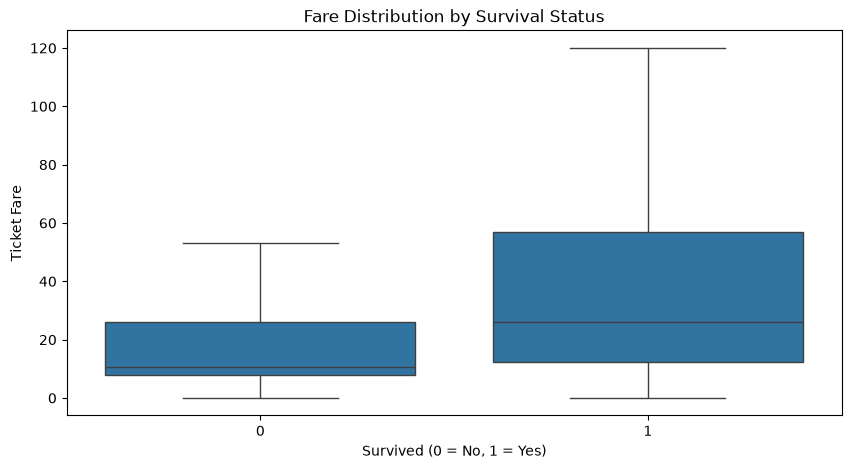


Survival Rate by Fare Group:
                 count   mean
FareGroup                    
(-0.001, 7.91]     223  19.73
(7.91, 14.454]     224  30.36
(14.454, 31.0]     222  45.50
(31.0, 512.329]    222  58.11


In [48]:
##Fare vs. survival
##Did passengers who paid higher fares have a greater probability of survival?


# Fare summary by survival status
fare_summary = train_clean_df.groupby(
    "Survived"
)["Fare"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print("Fare Statistics by Survival:")
print(fare_summary.round(2))

# Compare fare distributions
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_clean_df,
    x="Survived",
    y="Fare",
    showfliers=False
)

plt.title("Fare Distribution by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")
plt.show()

# Create fare quartiles for EDA
train_clean_df["FareGroup"] = pd.qcut(
    train_clean_df["Fare"],
    q=4,
    duplicates="drop"
)

fare_survival = train_clean_df.groupby(
    "FareGroup", observed=True
)["Survived"].agg(["count", "mean"])

fare_survival["mean"] *= 100

print("\nSurvival Rate by Fare Group:")
print(fare_survival.round(2))



The analysis revealed a positive association between ticket fare and survival probability. Survivors paid an average fare of 48.40, compared with 22.12 for non-survivors, while median fares were 26.00 and 10.50, respectively. Survival rates increased consistently across fare quartiles, from 19.73% in the lowest quartile to 58.11% in the highest quartile. These findings suggest that passengers paying higher fares were more likely to survive. However, since fare is strongly associated with passenger class, further analysis is needed to determine whether it provides additional predictive information beyond Pclass.

          Passengers  Survived  SurvivalRate
Embarked                                    
C                168        93         55.36
Q                 77        30         38.96
S                646       219         33.90


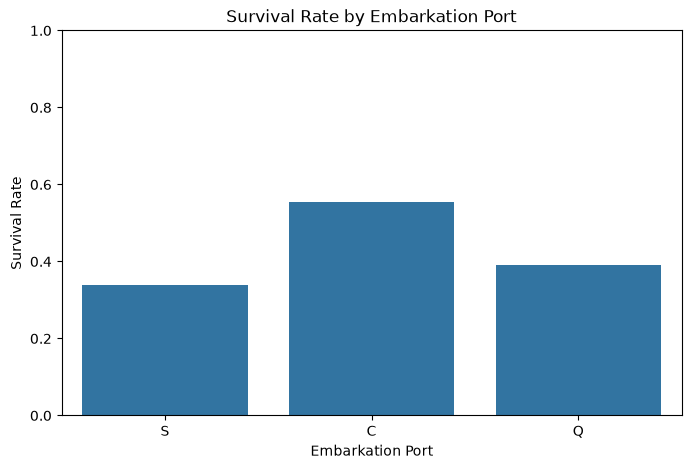

In [49]:
##Embarked vs. survival
##nvestigate whether the port where passengers boarded was associated with survival.


# Survival statistics by embarkation port
embarked_survival = train_clean_df.groupby(
    "Embarked"
)["Survived"].agg(["count", "sum", "mean"])

embarked_survival.columns = [
    "Passengers", "Survived", "SurvivalRate"
]

embarked_survival["SurvivalRate"] *= 100

print(embarked_survival.round(2))

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train_clean_df,
    x="Embarked",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()

Survival rates varied across the three embarkation ports. Passengers boarding at Cherbourg (C) had the highest survival rate at 55.36%, followed by Queenstown (Q) at 38.96% and Southampton (S) at 33.90%. Southampton accounted for the largest number of passengers (646), while Cherbourg and Queenstown accounted for 168 and 77, respectively. These differences suggest that embarkation port may contain useful predictive information, although variations in passenger class, fare, and demographics could explain part of the observed relationship. Therefore, Embarked will be retained as a candidate feature for modeling.

         Passengers  Survived  SurvivalRate
Deck                                       
A                15         7         46.67
B                47        35         74.47
C                59        35         59.32
D                33        25         75.76
E                32        24         75.00
F                13         8         61.54
G                 4         2         50.00
T                 1         0          0.00
Unknown         687       206         29.99


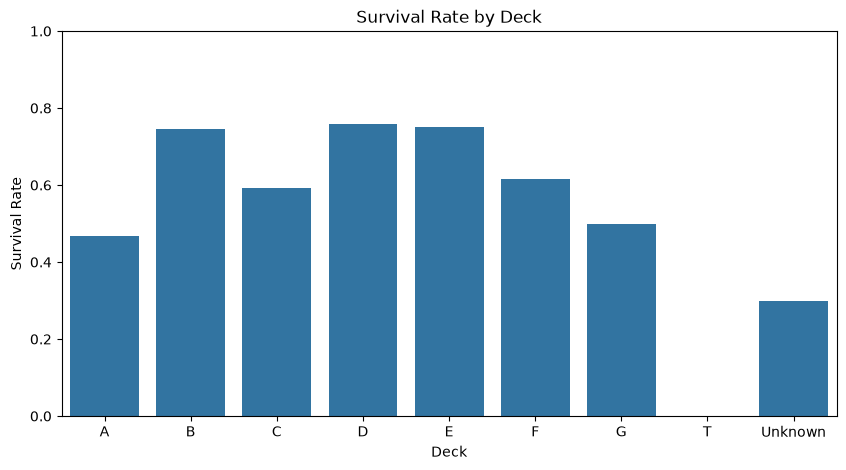

In [50]:
##Deck vs. survival

# Survival rates by deck
deck_survival = train_clean_df.groupby(
    "Deck"
)["Survived"].agg(["count", "sum", "mean"])

deck_survival.columns = [
    "Passengers", "Survived", "SurvivalRate"
]

deck_survival["SurvivalRate"] *= 100

print(deck_survival.round(2))

# Visualize
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train_clean_df,
    x="Deck",
    y="Survived",
    errorbar=None,
    order=sorted(train_clean_df["Deck"].unique())
)

plt.title("Survival Rate by Deck")
plt.xlabel("Deck")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()


The analysis identified substantial differences in survival rates across passenger decks. Decks D (75.76%), E (75.00%), and B (74.47%) had the highest observed survival rates, while passengers with unknown cabin information had a considerably lower survival rate of 29.99%. The Unknown category represented 687 passengers, approximately 77.1% of the training dataset. This suggests that cabin availability and deck location may be associated with survival outcomes. However, several decks contained very few passengers, making their survival estimates less reliable. The engineered Deck and CabinKnown features will therefore be evaluated during model training to determine their predictive contribution.

**Feature Engineering and Selection**

Some features, such as FamilySize and IsAlone, were created only in the training dataset during EDA. We need to create them in the test dataset as well.

We'll also create LogFare because ticket fares have a right-skewed distribution.

In [51]:
# Apply the same feature engineering to both datasets
for df in [train_clean_df, test_clean_df]:

    # Family size including passenger
    df["FamilySize"] = (
        df["SibSp"] + df["Parch"] + 1
    )

    # Traveling alone indicator
    df["IsAlone"] = (
        df["FamilySize"] == 1
    ).astype(int)

    # Log transform of fare
    df["LogFare"] = np.log1p(df["Fare"])

# Verify newly created features
print(train_clean_df[
    ["FamilySize", "IsAlone", "Fare", "LogFare"]
].head())

print("\nTest dataset:")
print(test_clean_df[
    ["FamilySize", "IsAlone", "Fare", "LogFare"]
].head())

   FamilySize  IsAlone     Fare   LogFare
0           2        0   7.2500  2.110213
1           2        0  71.2833  4.280593
2           1        1   7.9250  2.188856
3           2        0  53.1000  3.990834
4           1        1   8.0500  2.202765

Test dataset:
   FamilySize  IsAlone     Fare   LogFare
0           2        0   7.2500  2.110213
1           2        0  71.2833  4.280593
2           1        1   7.9250  2.188856
3           2        0  53.1000  3.990834
4           1        1   8.0500  2.202765


In [52]:
##Examine correlations among numerical features

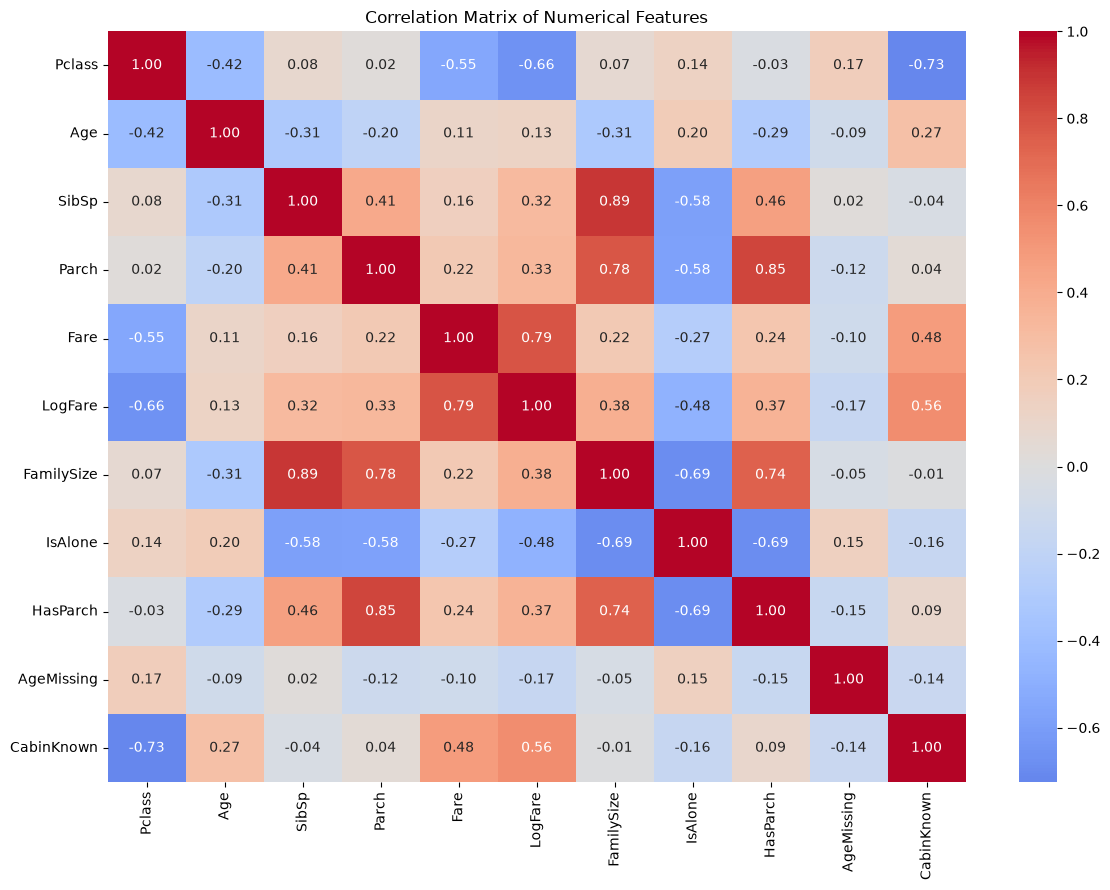

In [53]:

# Select numerical candidate features
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "LogFare",
    "FamilySize",
    "IsAlone",
    "HasParch",
    "AgeMissing",
    "CabinKnown"
]

# Correlation matrix
corr_matrix = train_clean_df[
    numeric_features
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


The correlation matrix revealed several strong relationships among the numerical features, indicating potential multicollinearity. FamilySize was highly correlated with SibSp (r = 0.89) and Parch (r = 0.78), which is expected because it was derived from these variables. Similarly, HasParch showed a strong positive correlation with Parch (r = 0.85), while Fare and LogFare were strongly correlated (r = 0.79). A strong negative correlation was observed between Pclass and CabinKnown (r = -0.73), suggesting that higher-class passengers were more likely to have recorded cabin information. These findings highlight potential redundancy among engineered features, particularly for linear models such as Logistic Regression. Therefore, we will evaluate alternative feature combinations to reduce unnecessary multicollinearity while preserving predictive information.

Correlation with Survival:
Pclass       -0.338
LogFare       0.330
CabinKnown    0.317
Fare          0.257
IsAlone      -0.203
HasParch      0.147
AgeMissing   -0.092
Parch         0.082
Age          -0.053
SibSp        -0.035
FamilySize    0.017
Name: Survived, dtype: float64


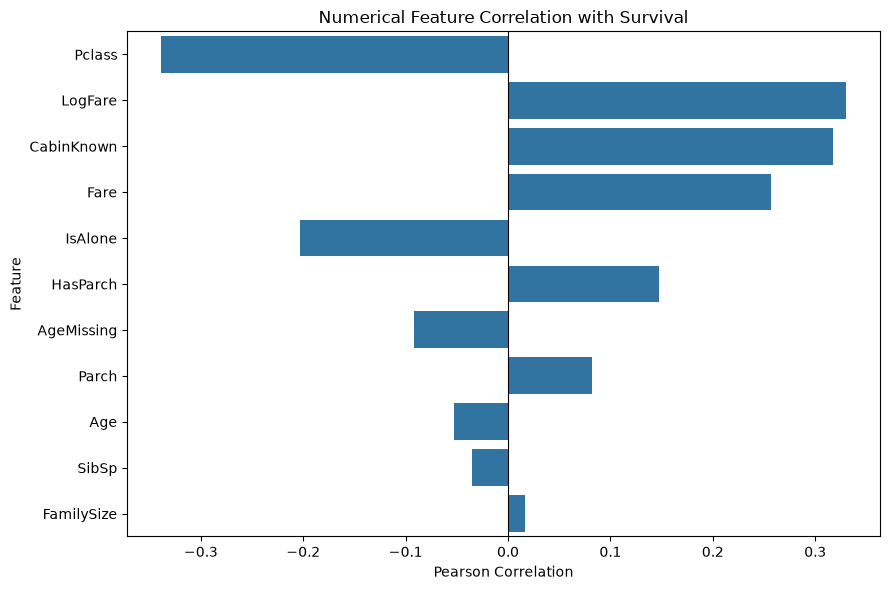

In [54]:
##Check correlations with survival


# Correlation with target
target_corr = train_clean_df[
    numeric_features + ["Survived"]
].corr()["Survived"].drop("Survived")

# Sort by absolute correlation
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(
        ascending=False
    ).index
)

print("Correlation with Survival:")
print(target_corr.round(3))

# Plot
plt.figure(figsize=(9, 6))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Numerical Feature Correlation with Survival")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


The correlation analysis identified Pclass (r = -0.338), LogFare (r = 0.330), and CabinKnown (r = 0.317) as the numerical features most strongly associated with survival. The negative correlation for Pclass indicates that passengers in higher ticket classes (represented by lower numerical values) were more likely to survive. Higher ticket fares and recorded cabin information were also positively associated with survival. IsAlone showed a moderate negative correlation (r = -0.203), suggesting that passengers traveling alone were less likely to survive. In contrast, Age (r = -0.053) and FamilySize (r = 0.017) demonstrated weak linear correlations with survival. However, weak Pearson correlations do not necessarily indicate low predictive value, as these features may have nonlinear relationships or interactions with other variables. These results provide an initial basis for feature selection, but final decisions will be guided by cross-validated model performance.

In [55]:
##Prepare Features for Machine Learning
##Create our baseline feature matrices

# Define features
categorical_features = [
    "Sex",
    "Pclass",
    "Embarked",
    "Title"
]

numeric_features = [
    "Age",
    "LogFare",
    "FamilySize",
    "IsAlone",
    "AgeMissing",
    "CabinKnown"
]

selected_features = (
    categorical_features + numeric_features
)

# Prepare feature matrices
X = train_clean_df[selected_features].copy()
y = train_clean_df["Survived"].copy()

X_test = test_clean_df[selected_features].copy()

print("Training features:", X.shape)
print("Training target:", y.shape)
print("Test features:", X_test.shape)

print("\nSelected features:")
print(selected_features)



Training features: (891, 10)
Training target: (891,)
Test features: (891, 10)

Selected features:
['Sex', 'Pclass', 'Embarked', 'Title', 'Age', 'LogFare', 'FamilySize', 'IsAlone', 'AgeMissing', 'CabinKnown']


In [56]:
#Build a preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            categorical_transformer,
            categorical_features
        ),
        (
            "num",
            numeric_transformer,
            numeric_features
        )
    ]
)

# Logistic Regression pipeline
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Preprocessing pipeline created successfully.")




Preprocessing pipeline created successfully.


In [57]:
##Train and evaluate Logistic Regression

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# Custom feature engineering and age imputation
class TitanicFeatures(BaseEstimator, TransformerMixin):

    def prepare(self, X):
        df = X.copy()

        df["AgeMissing"] = df["Age"].isna().astype(int)
        df["HasParch"] = (df["Parch"] > 0).astype(int)

        df["Title"] = df["Name"].str.extract(
            r",\s*([^.]+)\."
        )[0].str.strip()

        df["Title"] = df["Title"].replace({
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        })

        df["Title"] = df["Title"].where(
            df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]),
            "Rare"
        )

        df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
        df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
        df["CabinKnown"] = df["Cabin"].notna().astype(int)

        return df

    def fit(self, X, y=None):
        df = self.prepare(X)

        self.age_groups_ = [
            "Sex", "Pclass", "HasParch", "Title"
        ]

        self.age_medians_ = df.groupby(
            self.age_groups_
        )["Age"].median()

        self.fallback_ = df.groupby(
            ["Sex", "Pclass"]
        )["Age"].median()

        self.overall_age_ = df["Age"].median()

        self.fare_medians_ = df.groupby(
            "Pclass"
        )["Fare"].median()

        self.overall_fare_ = df["Fare"].median()
        self.embarked_mode_ = df["Embarked"].mode()[0]

        return self

    def transform(self, X):
        df = self.prepare(X)

        def fill_age(row):
            if pd.notna(row["Age"]):
                return row["Age"]

            key = tuple(row[c] for c in self.age_groups_)
            estimate = self.age_medians_.get(key, np.nan)

            if pd.isna(estimate):
                estimate = self.fallback_.get(
                    (row["Sex"], row["Pclass"]),
                    self.overall_age_
                )

            return estimate

        df["Age"] = df.apply(fill_age, axis=1)

        df["Fare"] = df["Fare"].fillna(
            df["Pclass"].map(self.fare_medians_)
        ).fillna(self.overall_fare_)

        df["Embarked"] = df["Embarked"].fillna(
            self.embarked_mode_
        )

        df["LogFare"] = np.log1p(df["Fare"])

        return df

# Raw training data
X = train_data_df.drop(columns=["Survived"]).copy()
y = train_data_df["Survived"].copy()

print("Training shape:", X.shape)
print("Target shape:", y.shape)


Training shape: (891, 11)
Target shape: (891,)


In [58]:
#Logestic regression
categorical_features = [
    "Sex", "Pclass", "Embarked", "Title"
]

numeric_features = [
    "Age", "LogFare", "FamilySize",
    "IsAlone", "AgeMissing", "CabinKnown"
]

preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        StandardScaler(),
        numeric_features
    )
])

logistic_pipeline = Pipeline([
    ("features", TitanicFeatures()),
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression pipeline ready.")

Logistic Regression pipeline ready.


In [60]:
##Train and evaluate with Stratified K-Fold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

cv_results = cross_validate(
    logistic_pipeline,
    X,
    y,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression - 5-Fold CV Results")
print("-" * 45)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric:12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )


Logistic Regression - 5-Fold CV Results
---------------------------------------------
Accuracy    : 0.8305 (+/- 0.0123)
Precision   : 0.7921 (+/- 0.0147)
Recall      : 0.7571 (+/- 0.0315)
F1          : 0.7739 (+/- 0.0199)
ROC_AUC     : 0.8753 (+/- 0.0177)


In [61]:
#Examine accuracy across individual folds

fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_Accuracy"],
    "Precision": cv_results["test_Precision"],
    "Recall": cv_results["test_Recall"],
    "F1": cv_results["test_F1"],
    "ROC_AUC": cv_results["test_ROC_AUC"]
})

print(fold_results.round(4))

print("\nAverage accuracy:",
      round(fold_results["Accuracy"].mean(), 4))

   Fold  Accuracy  Precision  Recall      F1  ROC_AUC
0     1    0.8492     0.8088  0.7971  0.8029   0.8985
1     2    0.8202     0.7727  0.7500  0.7612   0.8758
2     3    0.8146     0.7869  0.7059  0.7442   0.8531
3     4    0.8371     0.8095  0.7500  0.7786   0.8582
4     5    0.8315     0.7826  0.7826  0.7826   0.8908

Average accuracy: 0.8305


A Logistic Regression classification model was developed to predict Titanic passenger survival using engineered passenger features and a preprocessing pipeline. Model performance was evaluated using 5-fold Stratified Cross-Validation to preserve the target-class distribution across validation folds. The model achieved an average accuracy of 83.05% (±1.23 percentage points), substantially outperforming the majority-class baseline of 61.62%. Additional evaluation metrics included precision of 79.21%, recall of 75.71%, F1-score of 77.39%, and ROC-AUC of 0.8753. Accuracy across individual folds ranged from 81.46% to 84.92%, indicating relatively consistent predictive performance. The results demonstrate that Logistic Regression provides a strong initial baseline, although approximately 24% of actual survivors were not identified at the default classification threshold. Subsequent modeling will evaluate whether more flexible algorithms, including Random Forest and XGBoost, can improve predictive accuracy and capture nonlinear relationships among passenger characteristics.

In [62]:
##Train a Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

# Build Random Forest pipeline
rf_pipeline = Pipeline([
    ("features", TitanicFeatures()),
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate using the SAME cross-validation
rf_cv_results = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest - 5-Fold CV Results")
print("-" * 45)

for metric in scoring:
    scores = rf_cv_results[f"test_{metric}"]

    print(
        f"{metric:12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )


Random Forest - 5-Fold CV Results
---------------------------------------------
Accuracy    : 0.8271 (+/- 0.0132)
Precision   : 0.8227 (+/- 0.0261)
Recall      : 0.7017 (+/- 0.0306)
F1          : 0.7568 (+/- 0.0208)
ROC_AUC     : 0.8773 (+/- 0.0197)


In [63]:
##Compare Random Forest against Logistic Regression


comparison = pd.DataFrame({
    "Metric": list(scoring.keys()),

    "Logistic Regression": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],

    "Random Forest": [
        rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ]
})

comparison["Difference (RF - LR)"] = (
    comparison["Random Forest"]
    - comparison["Logistic Regression"]
)

print(comparison.round(4))


      Metric  Logistic Regression  Random Forest  Difference (RF - LR)
0   Accuracy               0.8305         0.8271               -0.0034
1  Precision               0.7921         0.8227                0.0306
2     Recall               0.7571         0.7017               -0.0554
3         F1               0.7739         0.7568               -0.0171
4    ROC_AUC               0.8753         0.8773                0.0020


A Random Forest classifier was trained and evaluated using 5-fold Stratified Cross-Validation with the same preprocessing pipeline and validation splits used for Logistic Regression. The model achieved an average accuracy of 82.71% (±1.32 percentage points), precision of 82.27%, recall of 70.17%, F1-score of 75.68%, and ROC-AUC of 0.8773. Compared with Logistic Regression, Random Forest demonstrated higher precision (+3.06 percentage points) and a marginally higher ROC-AUC (+0.0020), but lower accuracy (-0.34 percentage points), recall (-5.54 percentage points), and F1-score (-1.71 percentage points). These findings suggest that Random Forest produces more precise positive predictions but identifies fewer actual survivors at the default classification threshold. Overall, both models demonstrated comparable predictive performance, with Logistic Regression maintaining a slight advantage in accuracy, the primary evaluation metric for the Kaggle Titanic competition. Further evaluation using gradient boosting and hyperparameter optimization will determine whether predictive performance can be improved.

In [64]:
##Train an XGBoost Classifier


from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import numpy as np

# Build XGBoost pipeline
xgb_pipeline = Pipeline([
    ("features", TitanicFeatures()),
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate using the same 5-fold CV
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X,
    y,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

print("XGBoost - 5-Fold CV Results")
print("-" * 45)

for metric in scoring:
    scores = xgb_cv_results[f"test_{metric}"]

    print(
        f"{metric:12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )


XGBoost - 5-Fold CV Results
---------------------------------------------
Accuracy    : 0.8462 (+/- 0.0112)
Precision   : 0.8178 (+/- 0.0226)
Recall      : 0.7720 (+/- 0.0145)
F1          : 0.7940 (+/- 0.0138)
ROC_AUC     : 0.8838 (+/- 0.0201)


In [65]:
##Compare models

model_results = {
    "Logistic Regression": cv_results,
    "Random Forest": rf_cv_results,
    "XGBoost": xgb_cv_results
}

comparison = pd.DataFrame({
    model_name: {
        metric: results[f"test_{metric}"].mean()
        for metric in scoring
    }
    for model_name, results in model_results.items()
})

print("Model Comparison:")
print(comparison.round(4))

print("\nBest model by accuracy:")
print(comparison.loc["Accuracy"].idxmax())


Model Comparison:
           Logistic Regression  Random Forest  XGBoost
Accuracy                0.8305         0.8271   0.8462
Precision               0.7921         0.8227   0.8178
Recall                  0.7571         0.7017   0.7720
F1                      0.7739         0.7568   0.7940
ROC_AUC                 0.8753         0.8773   0.8838

Best model by accuracy:
XGBoost


An XGBoost classifier was developed and evaluated using 5-fold Stratified Cross-Validation with the same preprocessing pipeline and validation splits used for Logistic Regression and Random Forest. The model achieved an average accuracy of 84.62% (±1.12 percentage points), precision of 81.78%, recall of 77.20%, F1-score of 79.40%, and ROC-AUC of 0.8838. XGBoost outperformed both competing models in accuracy, recall, F1-score, and ROC-AUC, demonstrating its ability to capture nonlinear relationships and interactions among passenger characteristics. Compared with Logistic Regression, XGBoost improved accuracy by 1.57 percentage points and F1-score by 2.01 percentage points. Random Forest retained a marginal advantage in precision. Based on these cross-validation results, XGBoost was selected as the leading candidate for hyperparameter optimization. Further tuning and validation will be conducted to assess whether additional performance improvements can be achieved without overfitting.

In [66]:
##Hyperparameter Tuning for XGBoost


from sklearn.model_selection import RandomizedSearchCV
import pandas as pd

# Define hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

# Randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="accuracy",
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train and tune
random_search.fit(X, y)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(round(random_search.best_score_, 4))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'classifier__subsample': 0.7, 'classifier__reg_lambda': 3, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 3, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 1.0}

Best CV Accuracy:
0.8473


In [67]:
##Compare the tuned model with the original


original_accuracy = xgb_cv_results[
    "test_Accuracy"
].mean()

tuned_accuracy = random_search.best_score_

print(f"Original XGBoost: {original_accuracy:.4f}")
print(f"Tuned XGBoost:    {tuned_accuracy:.4f}")
print(f"Difference:       {tuned_accuracy - original_accuracy:+.4f}")

# Top 10 parameter combinations
tuning_results = pd.DataFrame(
    random_search.cv_results_
)

top_results = tuning_results[
    ["rank_test_score", "mean_test_score",
     "std_test_score", "params"]
].sort_values("rank_test_score").head(10)

print(top_results.to_string(index=False))


Original XGBoost: 0.8462
Tuned XGBoost:    0.8473
Difference:       +0.0011
 rank_test_score  mean_test_score  std_test_score                                                                                                                                                                                                                               params
               1         0.847329        0.027987   {'classifier__subsample': 0.7, 'classifier__reg_lambda': 3, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 3, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 1.0}
               2         0.845107        0.016981  {'classifier__subsample': 1.0, 'classifier__reg_lambda': 3, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 1, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1.0}
               3         0.843996        0.012501 {'classifier__subsample': 1.0, 'class

Hyperparameter optimization was performed using RandomizedSearchCV, evaluating 30 randomly selected parameter combinations through 5-fold Stratified Cross-Validation, resulting in 150 model evaluations. The search optimized classification accuracy across seven XGBoost hyperparameters, including the number of estimators, tree depth, learning rate, subsampling, feature sampling, minimum child weight, and L2 regularization. The best configuration used 500 estimators, a maximum tree depth of 2, a learning rate of 0.1, subsampling of 0.7, full feature sampling, a minimum child weight of 3, and an L2 regularization value of 3. The tuned model achieved 84.73% cross-validation accuracy, compared with 84.62% for the original XGBoost model, representing an improvement of only 0.11 percentage points. This marginal gain suggests that the original model was already reasonably well configured. Because the best score was also used for hyperparameter selection, additional validation is necessary before concluding that tuning improved generalization performance.

In [69]:
####Validate the Tuned Model on Unseen Folds


from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_score
)
import numpy as np

outer_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

original_scores = []
tuned_scores = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X, y), start=1
):
    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Original XGBoost
    original_model = xgb_pipeline
    original_model.fit(X_train, y_train)

    original_accuracy = original_model.score(
        X_val, y_val
    )
    original_scores.append(original_accuracy)

    # Tune using only outer training data
    search = RandomizedSearchCV(
        estimator=xgb_pipeline,
        param_distributions=param_distributions,
        n_iter=12,
        scoring="accuracy",
        cv=inner_cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    tuned_accuracy = search.best_estimator_.score(
        X_val, y_val
    )
    tuned_scores.append(tuned_accuracy)

    print(
        f"Fold {fold}: "
        f"Original={original_accuracy:.4f}, "
        f"Tuned={tuned_accuracy:.4f}"
    )

print("\nNested CV Summary")
print(f"Original: {np.mean(original_scores):.4f}")
print(f"Tuned:    {np.mean(tuned_scores):.4f}")
print(
    f"Difference: "
    f"{np.mean(tuned_scores)-np.mean(original_scores):+.4f}"
)


Fold 1: Original=0.8182, Tuned=0.8148
Fold 2: Original=0.8316, Tuned=0.8249
Fold 3: Original=0.8384, Tuned=0.8418

Nested CV Summary
Original: 0.8294
Tuned:    0.8272
Difference: -0.0022


Nested cross-validation was performed to evaluate whether hyperparameter tuning improved XGBoost's generalization performance. A 3-fold outer cross-validation procedure was used for model evaluation, while an inner 3-fold cross-validation procedure optimized hyperparameters using 12 randomly selected configurations within each outer training fold. The original XGBoost model achieved an average outer-fold accuracy of 82.94%, compared with 82.72% for the tuned model, representing a difference of 0.22 percentage points in favor of the original configuration. Although the tuned model achieved a slightly higher accuracy during the initial hyperparameter search, this improvement did not generalize to the nested validation experiment. Given the small performance difference and absence of consistent improvement from tuning, the original XGBoost configuration was selected for the initial Kaggle submission. This decision prioritizes generalization performance over optimization results that may be influenced by hyperparameter selection bias.

In [70]:
#Final XGBoost and Generate Kaggle Submission


import pandas as pd
import numpy as np
from sklearn.base import clone

# Create a fresh copy of the original XGBoost pipeline
final_model = clone(xgb_pipeline)

# Fit using all training passengers
final_model.fit(X, y)

# Use original test data
# Rename test_data_df if your test DataFrame has another name
X_test_final = test_data_df.copy()

# Predict survival: 0 = No, 1 = Yes
test_predictions = final_model.predict(X_test_final)

print("Total predictions:", len(test_predictions))
print("Predicted survivors:", np.sum(test_predictions == 1))
print("Predicted non-survivors:", np.sum(test_predictions == 0))


Total predictions: 891
Predicted survivors: 315
Predicted non-survivors: 576


In [71]:
submission = pd.DataFrame({
    "PassengerId": test_data_df["PassengerId"],
    "Survived": test_predictions.astype(int)
})

# Save Kaggle submission file
submission.to_csv("submission.csv", index=False)

# Verify submission
print(submission.head(10))
print("\nSubmission shape:", submission.shape)
print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction distribution:")
print(submission["Survived"].value_counts())


   PassengerId  Survived
0            1         0
1            2         1
2            3         1
3            4         1
4            5         0
5            6         0
6            7         0
7            8         0
8            9         1
9           10         1

Submission shape: (891, 2)

Missing values:
PassengerId    0
Survived       0
dtype: int64

Prediction distribution:
Survived
0    576
1    315
Name: count, dtype: int64


In [72]:
###Try to improve my model
###Test whether removing redundant features improves XGBoost


from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

# Original feature set
original_cat = [
    "Sex", "Pclass", "Embarked", "Title"
]

original_num = [
    "Age", "LogFare", "FamilySize",
    "IsAlone", "AgeMissing", "CabinKnown"
]

# Reduced feature set
reduced_cat = [
    "Sex", "Pclass", "Embarked", "Title"
]

reduced_num = [
    "Age", "LogFare", "FamilySize", "AgeMissing"
]

feature_sets = {
    "Original": (original_cat, original_num),
    "Reduced": (reduced_cat, reduced_num)
}

results = {}

for name, (cat_cols, num_cols) in feature_sets.items():

    # Create preprocessing for this feature set
    transformer = ColumnTransformer([
        ("cat", OneHotEncoder(
            handle_unknown="ignore"
        ), cat_cols),
        ("num", StandardScaler(), num_cols)
    ])

    # Clone the original model
    model = clone(xgb_pipeline)

    # Replace preprocessing
    model.set_params(preprocessor=transformer)

    # Same 5-fold cross-validation
    scores = cross_val_score(
        model,
        X,
        y,
        cv=skf,
        scoring="accuracy",
        n_jobs=-1
    )

    results[name] = scores.mean()

    print(
        f"{name}: {scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )

print("\nComparison:")
print(pd.Series(results).sort_values(ascending=False))


Original: 0.8462 (+/- 0.0112)
Reduced: 0.8462 (+/- 0.0100)

Comparison:
Original    0.846224
Reduced     0.846224
dtype: float64


A feature selection experiment was conducted to investigate whether removing potentially redundant variables would improve XGBoost performance. The original model included 10 input features, while the reduced model excluded IsAlone and CabinKnown, retaining eight features. Both configurations achieved identical mean accuracy of 84.62% using 5-fold Stratified Cross-Validation. The reduced model exhibited slightly lower variation across folds, with a standard deviation of 1.00 percentage points compared with 1.12 percentage points for the original model. These results suggest that the excluded features did not provide additional classification accuracy under the current model configuration. However, identical accuracy does not imply that the features contain no predictive information. The reduced configuration was retained as a simpler alternative for further experimentation.

In [73]:
#Ticket-Based Feature Engineering Group similar ticket numbers together


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

class TicketGroupFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = (
            X["Ticket"].fillna("Unknown")
            .astype(str)
            .value_counts()
            .to_dict()
        )
        return self

    def transform(self, X):
        X = X.copy()

        tickets = (
            X["Ticket"]
            .fillna("Unknown")
            .astype(str)
        )

        # Add the passenger's own ticket occurrence
        # when transforming unseen rows.
        X["TicketGroupSize"] = (
            tickets.map(self.ticket_counts_)
            .fillna(0)
            .astype(int) + 1
        )

        return X




In [74]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ticket_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     reduced_cat),
    ("num", StandardScaler(),
     reduced_num + ["TicketGroupSize"])
])

ticket_pipeline = Pipeline([
    ("ticket_features", TicketGroupFeatures()),
    ("features", TitanicFeatures()),
    ("preprocessor", ticket_preprocessor),
    ("classifier", clone(
        xgb_pipeline.named_steps["classifier"]
    ))
])

ticket_scores = cross_val_score(
    ticket_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost Accuracy: 0.8462")
print(
    f"Ticket Feature Accuracy: "
    f"{ticket_scores.mean():.4f} "
    f"(+/- {ticket_scores.std():.4f})"
)


Original XGBoost Accuracy: 0.8462
Ticket Feature Accuracy: 0.8406 (+/- 0.0133)


A ticket-based feature engineering experiment was conducted to investigate whether passengers sharing ticket numbers provided additional predictive information. A new variable, TicketGroupSize, was introduced into the XGBoost pipeline and evaluated using 5-fold Stratified Cross-Validation. The resulting model achieved 84.06% accuracy, compared with 84.62% for the original XGBoost model, representing a decrease of 0.56 percentage points. The ticket-based model also exhibited slightly greater variability across validation folds. These preliminary findings suggest that the ticket-count feature, as initially implemented, did not improve predictive performance. However, because the initial implementation used an approximate ticket-count definition, further refinement is required before concluding that ticket-sharing information lacks predictive value.

In [75]:
##Improve Family Feature Engineering


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

class FamilyCategoryFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        family_size = X["SibSp"] + X["Parch"] + 1

        X["FamilyCategory"] = pd.cut(
            family_size,
            bins=[0, 1, 4, float("inf")],
            labels=["Alone", "Small", "Large"]
        ).astype(str)

        return X


family_cat = reduced_cat + ["FamilyCategory"]
family_num = reduced_num

family_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), family_cat),
    ("num", StandardScaler(), family_num)
])

family_pipeline = Pipeline([
    ("family_features", FamilyCategoryFeatures()),
    ("features", TitanicFeatures()),
    ("preprocessor", family_preprocessor),
    ("classifier", clone(
        xgb_pipeline.named_steps["classifier"]
    ))
])

family_scores = cross_val_score(
    family_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost: 0.8462")
print(
    f"Family Category XGBoost: "
    f"{family_scores.mean():.4f} "
    f"(+/- {family_scores.std():.4f})"
)


Original XGBoost: 0.8462
Family Category XGBoost: 0.8462 (+/- 0.0142)


 categorical family-size feature was introduced to evaluate whether explicitly grouping passengers into three categories—Alone, Small Family (2–4 members), and Large Family (5 or more members)—would improve XGBoost performance. The feature was added alongside the existing numerical FamilySize variable and evaluated using 5-fold Stratified Cross-Validation. The model achieved 84.62% accuracy, identical to the original XGBoost model, while its cross-validation standard deviation increased from 1.12 to 1.42 percentage points. These results suggest that the original numerical family-size feature may already capture the relevant nonlinear relationships, making the additional categorical representation unnecessary under the current model configuration.

In [76]:
##Engineer Child and Mother Features


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score

class PassengerGroupFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["IsChild"] = (
            X["Age"] < 13
        ).astype(int)

        X["IsMother"] = (
            (X["Sex"] == "female") &
            (X["Age"] >= 18) &
            (X["Parch"] > 0) &
            (X["Title"] == "Mrs")
        ).astype(int)

        return X


passenger_cat = reduced_cat

passenger_num = reduced_num + [
    "IsChild", "IsMother"
]

passenger_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     passenger_cat),
    ("num", StandardScaler(), passenger_num)
])

passenger_pipeline = Pipeline([
    ("features", TitanicFeatures()),
    ("passenger_groups", PassengerGroupFeatures()),
    ("preprocessor", passenger_preprocessor),
    ("classifier", clone(
        xgb_pipeline.named_steps["classifier"]
    ))
])

passenger_scores = cross_val_score(
    passenger_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost: 0.8462")
print(
    f"Child + Mother Features: "
    f"{passenger_scores.mean():.4f} "
    f"(+/- {passenger_scores.std():.4f})"
)


Original XGBoost: 0.8462
Child + Mother Features: 0.8417 (+/- 0.0141)


Two additional binary features, IsChild and IsMother, were engineered to investigate whether explicitly identifying children and likely mothers could improve survival prediction. The features were derived from passenger age, gender, title, and family relationships, with missing ages imputed within the cross-validation pipeline. The enhanced XGBoost model achieved 84.17% accuracy using 5-fold Stratified Cross-Validation, compared with 84.62% for the original model, representing a decrease of 0.45 percentage points. The model also exhibited slightly greater variability across validation folds. These findings suggest that the existing features already capture much of the predictive information associated with passenger age and family characteristics. Consequently, the original XGBoost configuration remains the preferred model among the feature-engineering experiments evaluated so far.

In [78]:
###lets try Try CatBoost


In [81]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

cat_features = ["Sex", "Pclass", "Embarked", "Title"]

catboost_features = cat_features + [
    "Age", "LogFare", "FamilySize",
    "IsAlone", "AgeMissing", "CabinKnown"
]

catboost_scores = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1": [],
    "ROC_AUC": []
}

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    X_train = X.iloc[train_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Fit preprocessing only on training fold
    feature_engineer = TitanicFeatures()
    feature_engineer.fit(X_train)

    X_train_processed = feature_engineer.transform(
        X_train
    )[catboost_features].copy()

    X_val_processed = feature_engineer.transform(
        X_val
    )[catboost_features].copy()

    # Convert categorical features to strings
    for col in cat_features:
        X_train_processed[col] = (
            X_train_processed[col].astype(str)
        )
        X_val_processed[col] = (
            X_val_processed[col].astype(str)
        )

    # Initialize a fresh model for each fold
    model = CatBoostClassifier(
        iterations=500,
        depth=4,
        learning_rate=0.03,
        l2_leaf_reg=3,
        loss_function="Logloss",
        verbose=False,
        random_seed=42,
        thread_count=1
    )

    model.fit(
        X_train_processed,
        y_train,
        cat_features=cat_features
    )

    # Predict
    y_pred = model.predict(
        X_val_processed
    ).astype(int).ravel()

    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Evaluate
    catboost_scores["Accuracy"].append(
        accuracy_score(y_val, y_pred)
    )
    catboost_scores["Precision"].append(
        precision_score(y_val, y_pred)
    )
    catboost_scores["Recall"].append(
        recall_score(y_val, y_pred)
    )
    catboost_scores["F1"].append(
        f1_score(y_val, y_pred)
    )
    catboost_scores["ROC_AUC"].append(
        roc_auc_score(y_val, y_prob)
    )

    print(
        f"Fold {fold}: "
        f"Accuracy = {accuracy_score(y_val, y_pred):.4f}"
    )

# Store results in same format as previous models
catboost_cv_results = {
    f"test_{metric}": np.array(scores)
    for metric, scores in catboost_scores.items()
}

print("\nCatBoost - 5-Fold CV Results")
print("-" * 40)

for metric in scoring:
    scores = catboost_cv_results[f"test_{metric}"]
    print(
        f"{metric:12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )



Fold 1: Accuracy = 0.8547
Fold 2: Accuracy = 0.8708
Fold 3: Accuracy = 0.8146
Fold 4: Accuracy = 0.8315
Fold 5: Accuracy = 0.8371

CatBoost - 5-Fold CV Results
----------------------------------------
Accuracy    : 0.8417 (+/- 0.0194)
Precision   : 0.8300 (+/- 0.0319)
Recall      : 0.7397 (+/- 0.0320)
F1          : 0.7819 (+/- 0.0279)
ROC_AUC     : 0.8793 (+/- 0.0202)


In [82]:
##Compare


comparison = pd.DataFrame({
    "XGBoost": {
        metric: xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "CatBoost": {
        metric: catboost_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    }
})

comparison["Difference (CatBoost - XGBoost)"] = (
    comparison["CatBoost"] - comparison["XGBoost"]
)

print(comparison.round(4))


           XGBoost  CatBoost  Difference (CatBoost - XGBoost)
Accuracy    0.8462    0.8417                          -0.0045
Precision   0.8178    0.8300                           0.0122
Recall      0.7720    0.7397                          -0.0323
F1          0.7940    0.7819                          -0.0121
ROC_AUC     0.8838    0.8793                          -0.0045


A CatBoost classifier was developed to evaluate whether native categorical feature handling could improve Titanic survival prediction. The model was evaluated using 5-fold Stratified Cross-Validation with the same validation splits and fold-specific feature engineering used for the previous models. CatBoost achieved an average accuracy of 84.17%, precision of 83.00%, recall of 73.97%, F1-score of 78.19%, and ROC-AUC of 0.8793. Compared with XGBoost, CatBoost demonstrated higher precision but lower accuracy, recall, F1-score, and ROC-AUC. XGBoost maintained an accuracy advantage of 0.45 percentage points. Although CatBoost performed competitively, the original XGBoost model remained the strongest overall candidate based on the current cross-validation results.

In [83]:
#Ensemble


from sklearn.base import clone
from sklearn.metrics import accuracy_score
from catboost import CatBoostClassifier
import numpy as np

ensemble_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    X_train = X.iloc[train_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Logistic Regression
    lr_model = clone(logistic_pipeline)
    lr_model.fit(X_train, y_train)
    lr_prob = lr_model.predict_proba(X_val)[:, 1]

    # XGBoost
    xgb_model = clone(xgb_pipeline)
    xgb_model.fit(X_train, y_train)
    xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

    # CatBoost with fold-specific preprocessing
    engineer = TitanicFeatures()
    engineer.fit(X_train)

    X_train_cat = engineer.transform(
        X_train
    )[catboost_features].copy()

    X_val_cat = engineer.transform(
        X_val
    )[catboost_features].copy()

    for col in cat_features:
        X_train_cat[col] = X_train_cat[col].astype(str)
        X_val_cat[col] = X_val_cat[col].astype(str)

    cat_model = CatBoostClassifier(
        iterations=500,
        depth=4,
        learning_rate=0.03,
        l2_leaf_reg=3,
        loss_function="Logloss",
        verbose=False,
        random_seed=42,
        thread_count=1
    )

    cat_model.fit(
        X_train_cat,
        y_train,
        cat_features=cat_features
    )

    cat_prob = cat_model.predict_proba(
        X_val_cat
    )[:, 1]

    # Equal-weight soft voting
    ensemble_prob = (
        lr_prob + xgb_prob + cat_prob
    ) / 3

    ensemble_pred = (
        ensemble_prob >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_val, ensemble_pred
    )

    ensemble_scores.append(accuracy)

    print(f"Fold {fold}: {accuracy:.4f}")

print("\nEnsemble Results")
print(
    f"Mean Accuracy: {np.mean(ensemble_scores):.4f}"
)
print(
    f"Standard Deviation: {np.std(ensemble_scores):.4f}"
)
print(
    f"Original XGBoost: "
    f"{xgb_cv_results['test_Accuracy'].mean():.4f}"
)


Fold 1: 0.8492
Fold 2: 0.8483
Fold 3: 0.8146
Fold 4: 0.8427
Fold 5: 0.8539

Ensemble Results
Mean Accuracy: 0.8417
Standard Deviation: 0.0140
Original XGBoost: 0.8462


A soft-voting ensemble was developed by combining the predicted survival probabilities from Logistic Regression, XGBoost, and CatBoost using equal weights. The ensemble was evaluated using 5-fold Stratified Cross-Validation with consistent validation splits and fold-specific preprocessing. The resulting model achieved an average accuracy of 84.17%, with a standard deviation of 1.40 percentage points. This was slightly lower than the original XGBoost model's accuracy of 84.62%. The results indicate that combining the three models through equal-weight probability averaging did not improve predictive performance. Potential explanations include correlated prediction errors and the influence of weaker individual models. Consequently, the original XGBoost model remains the preferred candidate based on the current cross-validation experiments.

In [84]:
#weighted ensembles


from sklearn.base import clone
from sklearn.metrics import accuracy_score
from catboost import CatBoostClassifier
import numpy as np
import pandas as pd

weights_to_test = {
    "Equal": [1/3, 1/3, 1/3],
    "XGBoost 60%": [0.2, 0.6, 0.2],
    "XGBoost 80%": [0.1, 0.8, 0.1]
}

weighted_results = {
    name: [] for name in weights_to_test
}

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    X_train = X.iloc[train_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Logistic Regression
    lr = clone(logistic_pipeline)
    lr.fit(X_train, y_train)
    lr_prob = lr.predict_proba(X_val)[:, 1]

    # XGBoost
    xgb = clone(xgb_pipeline)
    xgb.fit(X_train, y_train)
    xgb_prob = xgb.predict_proba(X_val)[:, 1]

    # CatBoost
    engineer = TitanicFeatures()
    engineer.fit(X_train)

    train_cat = engineer.transform(
        X_train
    )[catboost_features].copy()

    val_cat = engineer.transform(
        X_val
    )[catboost_features].copy()

    for col in cat_features:
        train_cat[col] = train_cat[col].astype(str)
        val_cat[col] = val_cat[col].astype(str)

    cat = CatBoostClassifier(
        iterations=500,
        depth=4,
        learning_rate=0.03,
        l2_leaf_reg=3,
        loss_function="Logloss",
        verbose=False,
        random_seed=42,
        thread_count=1
    )

    cat.fit(
        train_cat,
        y_train,
        cat_features=cat_features
    )

    cat_prob = cat.predict_proba(
        val_cat
    )[:, 1]

    probabilities = np.column_stack([
        lr_prob, xgb_prob, cat_prob
    ])

    # Evaluate each weight combination
    for name, weights in weights_to_test.items():
        avg_prob = probabilities @ np.array(weights)
        predictions = (avg_prob >= 0.5).astype(int)

        weighted_results[name].append(
            accuracy_score(y_val, predictions)
        )

# Summary
summary = pd.DataFrame({
    "Mean Accuracy": {
        name: np.mean(scores)
        for name, scores in weighted_results.items()
    },
    "Std Dev": {
        name: np.std(scores)
        for name, scores in weighted_results.items()
    }
})

print(summary.round(4))
print(
    "\nOriginal XGBoost:",
    round(xgb_cv_results["test_Accuracy"].mean(), 4)
)


             Mean Accuracy  Std Dev
Equal               0.8417   0.0140
XGBoost 60%         0.8440   0.0121
XGBoost 80%         0.8462   0.0112

Original XGBoost: 0.8462


A weighted soft-voting experiment was conducted to determine whether assigning greater importance to XGBoost would improve ensemble classification accuracy. Three weighting configurations were evaluated using 5-fold Stratified Cross-Validation: equal weighting across Logistic Regression, XGBoost, and CatBoost; 60% weight assigned to XGBoost; and 80% weight assigned to XGBoost. The equal-weight ensemble achieved 84.17% accuracy, while the 60%-weighted configuration improved accuracy to 84.40%. Increasing XGBoost's contribution to 80% produced an accuracy of 84.62%, matching the standalone XGBoost model. These findings indicate that emphasizing the strongest individual classifier improved ensemble performance, but did not provide additional predictive gains beyond XGBoost alone. Therefore, the original XGBoost model was retained as the preferred solution based on the current experiments.

In [85]:
from sklearn.base import clone
import pandas as pd

# Use the original XGBoost pipeline
final_model = clone(xgb_pipeline)

# Train on all labeled Titanic passengers
final_model.fit(X, y)

# Predict survival for Kaggle test passengers
test_predictions = final_model.predict(test_data_df)

# Create submission
submission = pd.DataFrame({
    "PassengerId": test_data_df["PassengerId"],
    "Survived": test_predictions.astype(int)
})

# Save submission file
submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
print(submission.head())
print("\nPredicted survival distribution:")
print(submission["Survived"].value_counts())


Submission shape: (891, 2)
   PassengerId  Survived
0            1         0
1            2         1
2            3         1
3            4         1
4            5         0

Predicted survival distribution:
Survived
0    576
1    315
Name: count, dtype: int64


In [86]:
print("Training data:", train_data_df.shape)
print("Test data:", test_data_df.shape)
print("Submission:", submission.shape)

print("\nSubmission columns:")
print(submission.columns.tolist())

print("\nFirst five rows:")
print(submission.head())

Training data: (891, 12)
Test data: (891, 12)
Submission: (891, 2)

Submission columns:
['PassengerId', 'Survived']

First five rows:
   PassengerId  Survived
0            1         0
1            2         1
2            3         1
3            4         1
4            5         0


In [ ]:
###Apply model on Test data

In [87]:
import pandas as pd

# Load the original Kaggle test dataset
test_data_df = pd.read_csv("test.csv")

print("Training shape:", train_data_df.shape)
print("Test shape:", test_data_df.shape)

print("\nFirst 5 test passenger IDs:")
print(test_data_df["PassengerId"].head())

print("\nTest columns:")
print(test_data_df.columns.tolist())


Training shape: (891, 12)
Test shape: (418, 11)

First 5 test passenger IDs:
0    892
1    893
2    894
3    895
4    896
Name: PassengerId, dtype: int64

Test columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [88]:

from sklearn.base import clone
import pandas as pd

# Train on all 891 labeled passengers
final_model = clone(xgb_pipeline)
final_model.fit(X, y)

# Predict all 418 unseen test passengers
test_predictions = final_model.predict(test_data_df)

# Create submission
submission = pd.DataFrame({
    "PassengerId": test_data_df["PassengerId"].to_numpy(),
    "Survived": test_predictions.astype(int)
})

# Verify
assert submission.shape == (418, 2)
assert submission["PassengerId"].iloc[0] == 892
assert submission["PassengerId"].is_unique

# Export
submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
print(submission.head())
print("\nSaved file: submission.csv")

Submission shape: (418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1

Saved file: submission.csv


In [90]:
check = pd.read_csv("submission.csv")

print("CSV shape:", check.shape)
print("First PassengerId:", check["PassengerId"].iloc[0])
print("Last PassengerId:", check["PassengerId"].iloc[-1])
print("Missing values:", check.isna().sum().sum())


CSV shape: (418, 2)
First PassengerId: 892
Last PassengerId: 1309
Missing values: 0


In [91]:

# Apply the trained feature engineering transformer
test_engineered = final_model.named_steps[
    "features"
].transform(test_data_df)

print("Original test shape:", test_data_df.shape)
print("Engineered test shape:", test_engineered.shape)

# Display engineered features
columns_to_check = [
    "PassengerId",
    "Sex",
    "Pclass",
    "Age",
    "AgeMissing",
    "HasParch",
    "Title",
    "FamilySize",
    "IsAlone",
    "CabinKnown",
    "Fare",
    "LogFare",
    "Embarked"
]

display(test_engineered[columns_to_check].head(10))

print("\nMissing values in model features:")
print(
    test_engineered[
        categorical_features + numeric_features
    ].isnull().sum()
)

Original test shape: (418, 11)
Engineered test shape: (418, 18)


,PassengerId,Sex,Pclass,Age,AgeMissing,HasParch,Title,FamilySize,IsAlone,CabinKnown,Fare,LogFare,Embarked
0,892,male,3,34.5,0,0,Mr,1,1,0,7.8292,2.178064,Q
1,893,female,3,47.0,0,0,Mrs,2,0,0,7.0000,2.079442,S
2,894,male,2,62.0,0,0,Mr,1,1,0,9.6875,2.369075,Q
3,895,male,3,27.0,0,0,Mr,1,1,0,8.6625,2.268252,S
4,896,female,3,22.0,0,1,Mrs,3,0,0,12.2875,2.586824,S
5,897,male,3,14.0,0,0,Mr,1,1,0,9.2250,2.324836,S
6,898,female,3,30.0,0,0,Miss,1,1,0,7.6292,2.155152,Q
7,899,male,2,26.0,0,1,Mr,3,0,0,29.0000,3.401197,S
8,900,female,3,18.0,0,0,Mrs,1,1,0,7.2292,2.107689,C
9,901,male,3,21.0,0,0,Mr,3,0,0,24.1500,3.224858,S



Missing values in model features:
Sex           0
Pclass        0
Embarked      0
Title         0
Age           0
LogFare       0
FamilySize    0
IsAlone       0
AgeMissing    0
CabinKnown    0
dtype: int64


In [92]:

# Verify training and test datasets
print("Training shape:", train_data_df.shape)
print("Test shape:", test_data_df.shape)

# Apply trained feature engineering
train_features = final_model.named_steps[
    "features"
].transform(X)

test_features = final_model.named_steps[
    "features"
].transform(test_data_df)

# Compare key feature distributions
features_to_check = [
    "Age", "Fare", "LogFare",
    "FamilySize", "AgeMissing", "CabinKnown"
]

distribution_check = pd.DataFrame({
    "Train Mean": train_features[features_to_check].mean(),
    "Test Mean": test_features[features_to_check].mean(),
    "Train Missing": train_features[features_to_check].isna().sum(),
    "Test Missing": test_features[features_to_check].isna().sum()
})

print("\nFeature Distribution Comparison:")
display(distribution_check.round(3))

# Compare predicted survival proportions
print("\nActual training survival rate:")
print(y.mean().round(4))

print("\nPredicted test survival rate:")
print(submission["Survived"].mean().round(4))

print("\nPredictions by passenger sex:")
print(
    pd.crosstab(
        test_data_df["Sex"],
        submission["Survived"],
        normalize="index"
    ).round(3)
)


Training shape: (891, 12)
Test shape: (418, 11)

Feature Distribution Comparison:


,Train Mean,Test Mean,Train Missing,Test Missing
Age,29.073,29.415,0,0
Fare,32.204,35.561,0,0
LogFare,2.962,3.014,0,0
FamilySize,1.905,1.840,0,0
AgeMissing,0.199,0.206,0,0
CabinKnown,0.229,0.218,0,0



Actual training survival rate:
0.3838

Predicted test survival rate:
0.366

Predictions by passenger sex:
Survived      0      1
Sex                   
female    0.151  0.849
male      0.910  0.090


In [93]:
import pandas as pd
import numpy as np

# Predictions on training data
train_pred = final_model.predict(X).astype(int)

# Predictions on test data
test_pred = final_model.predict(test_data_df).astype(int)

# Actual survival rates by sex
actual_train = (
    train_data_df.groupby("Sex")["Survived"]
    .mean()
)

# Predicted survival rates by sex
predicted_train = pd.DataFrame({
    "Sex": X["Sex"],
    "Predicted": train_pred
}).groupby("Sex")["Predicted"].mean()

predicted_test = pd.DataFrame({
    "Sex": test_data_df["Sex"],
    "Predicted": test_pred
}).groupby("Sex")["Predicted"].mean()

comparison = pd.DataFrame({
    "Actual Train Survival": actual_train,
    "Predicted Train Survival": predicted_train,
    "Predicted Test Survival": predicted_test,
    "Train Count": X.groupby("Sex").size(),
    "Test Count": test_data_df.groupby("Sex").size()
})

print("Survival Comparison by Sex:")
display(comparison.round(4))

print("\nTraining accuracy:")
print(round((train_pred == y.to_numpy()).mean(), 4))


Survival Comparison by Sex:


,Actual Train Survival,Predicted Train Survival,Predicted Test Survival,Train Count,Test Count
Sex,,,,,
female,0.7420,0.8217,0.8487,314,152
male,0.1889,0.0988,0.0902,577,266



Training accuracy:
0.8956


Overfitting Analysis
Your results reveal something important: our XGBoost model shows evidence of overfitting, and it predicts survival more frequently for women than their observed survival rate in training.

In [94]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

configurations = {
    "Original": {
        "max_depth": 3,
        "n_estimators": 300,
        "learning_rate": 0.05,
        "min_child_weight": 1,
        "reg_lambda": 1
    },
    "Regularized": {
        "max_depth": 2,
        "n_estimators": 200,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "reg_lambda": 10
    },
    "Very Shallow": {
        "max_depth": 1,
        "n_estimators": 150,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "reg_lambda": 10
    }
}

complexity_results = []

for name, params in configurations.items():

    model = clone(xgb_pipeline)

    model.set_params(**{
        f"classifier__{key}": value
        for key, value in params.items()
    })

    scores = cross_validate(
        model,
        X,
        y,
        cv=skf,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    train_accuracy = scores["train_score"].mean()
    val_accuracy = scores["test_score"].mean()

    complexity_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "CV Accuracy": val_accuracy,
        "Gap": train_accuracy - val_accuracy
    })

results_df = pd.DataFrame(complexity_results)

print(results_df.round(4).to_string(index=False))


       Model  Train Accuracy  CV Accuracy    Gap
    Original          0.9040       0.8462 0.0578
 Regularized          0.8381       0.8193 0.0188
Very Shallow          0.8196       0.8092 0.0104


Three XGBoost configurations were evaluated to investigate the relationship between model complexity, overfitting, and predictive performance. The original model achieved 90.40% training accuracy and 84.62% cross-validation accuracy, resulting in a generalization gap of 5.78 percentage points. A more strongly regularized model reduced this gap to 1.88 percentage points but achieved lower cross-validation accuracy of 81.93%. A very shallow model further reduced the gap to 1.04 percentage points while decreasing cross-validation accuracy to 80.92%. These results indicate that stronger regularization successfully constrained model complexity but also reduced predictive performance, suggesting possible underfitting. Consequently, the original XGBoost configuration remains the strongest candidate among the tested complexity settings, although its lower Kaggle leaderboard score warrants further investigation.

In [95]:

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)
from sklearn.base import clone
import pandas as pd
import numpy as np

# Group passengers by ticket number
ticket_groups = (
    X["Ticket"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the original XGBoost model
group_scores = cross_validate(
    clone(xgb_pipeline),
    X,
    y,
    groups=ticket_groups,
    cv=group_cv,
    scoring=scoring,
    n_jobs=-1
)

print("Original Stratified 5-Fold CV:")
print(
    f"Accuracy: "
    f"{xgb_cv_results['test_Accuracy'].mean():.4f}"
)

print("\nTicket-Grouped 5-Fold CV:")
for metric in scoring:
    scores = group_scores[f"test_{metric}"]

    print(
        f"{metric:12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )



Original Stratified 5-Fold CV:
Accuracy: 0.8462

Ticket-Grouped 5-Fold CV:
Accuracy    : 0.8261 (+/- 0.0224)
Precision   : 0.8012 (+/- 0.0340)
Recall      : 0.7280 (+/- 0.0327)
F1          : 0.7626 (+/- 0.0303)
ROC_AUC     : 0.8579 (+/- 0.0344)


A ticket-grouped validation experiment was conducted using StratifiedGroupKFold to investigate whether passengers sharing ticket numbers across training and validation folds contributed to optimistic performance estimates. The original XGBoost model achieved 84.62% accuracy under standard Stratified 5-Fold Cross-Validation, compared with 82.61% accuracy under ticket-grouped validation. Precision decreased to 80.12%, recall to 72.80%, F1-score to 76.26%, and ROC-AUC to 0.8579. The 2.01-percentage-point decrease in accuracy suggests that passenger grouping may influence validation performance. However, the difference may also reflect changes in fold composition and does not establish data leakage. Grouped validation provides an additional assessment of model generalization, although the resulting accuracy remains higher than the Kaggle public leaderboard score of 76.315%.

In [96]:

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)
from sklearn.base import clone
import numpy as np

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

repeated_scores = cross_val_score(
    clone(xgb_pipeline),
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Repeated Stratified CV Results")
print("-" * 40)

print(f"Mean Accuracy: {repeated_scores.mean():.4f}")
print(f"Std Dev:       {repeated_scores.std():.4f}")
print(f"Minimum:       {repeated_scores.min():.4f}")
print(f"Maximum:       {repeated_scores.max():.4f}")

print("\nOriginal CV Accuracy: 0.8462")
print("Ticket-Grouped CV Accuracy: 0.8261")
print("Kaggle Public Score: 0.76315")


Repeated Stratified CV Results
----------------------------------------
Mean Accuracy: 0.8341
Std Dev:       0.0192
Minimum:       0.7921
Maximum:       0.8708

Original CV Accuracy: 0.8462
Ticket-Grouped CV Accuracy: 0.8261
Kaggle Public Score: 0.76315


Repeated Stratified Cross-Validation was performed using five folds repeated ten times, producing 50 validation accuracy measurements. The original XGBoost model achieved a mean accuracy of 83.41%, with a standard deviation of 1.92 percentage points and individual fold accuracies ranging from 79.21% to 87.08%. This was slightly lower than the initial 5-fold cross-validation accuracy of 84.62%, suggesting that the original validation split was somewhat favorable. Ticket-grouped validation produced an accuracy of 82.61%, while the Kaggle public leaderboard score was 76.315%. The results demonstrate that the model maintains relatively consistent performance across random training-validation splits, although a noticeable discrepancy remains between local validation and public leaderboard performance. Further investigation of preprocessing, feature importance, and model calibration may help identify potential improvements.

In [97]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import numpy as np

# Create a subclass using simpler age imputation
class SimpleAgeFeatures(TitanicFeatures):

    def fit(self, X, y=None):
        super().fit(X, y)

        # Learn simpler age medians from training fold
        self.simple_age_medians_ = (
            X.groupby(["Sex", "Pclass"])["Age"]
            .median()
        )

        return self

    def transform(self, X):
        X = super().transform(X)

        # Override imputed ages only for originally missing ages
        missing = X["AgeMissing"] == 1

        for idx in X.index[missing]:
            sex = X.at[idx, "Sex"]
            pclass = X.at[idx, "Pclass"]

            key = (sex, pclass)

            if key in self.simple_age_medians_.index:
                X.at[idx, "Age"] = (
                    self.simple_age_medians_.loc[key]
                )

        return X


simple_age_pipeline = clone(xgb_pipeline)

simple_age_pipeline.set_params(
    features=SimpleAgeFeatures()
)

simple_scores = cross_val_score(
    simple_age_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original Age Imputation: 0.8462")
print(
    f"Simple Age Imputation: "
    f"{simple_scores.mean():.4f} "
    f"(+/- {simple_scores.std():.4f})"
)


Original Age Imputation: 0.8462
Simple Age Imputation: 0.8451 (+/- 0.0128)


An experiment was conducted to assess whether simplifying missing-age imputation could improve XGBoost's predictive performance. The original approach estimated missing ages using passenger sex, class, parental relationships, and title, while the alternative used median ages grouped only by sex and passenger class. Both strategies were evaluated using 5-fold Stratified Cross-Validation with imputation statistics learned exclusively from each training fold. The original method achieved 84.62% accuracy, compared with 84.51% for the simplified approach, representing a negligible difference of 0.11 percentage points. These findings indicate that the more detailed imputation strategy provides little measurable improvement in survival prediction under the current configuration. The original method was retained, although neither strategy demonstrated a decisive advantage.

In [ ]:
#Feature importance

In [98]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import pandas as pd
import numpy as np

importance_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = clone(xgb_pipeline)
    model.fit(X_train, y_train)

    result = permutation_importance(
        model,
        X_val,
        y_val,
        scoring="accuracy",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(
        result.importances_mean
    )

# Aggregate across folds
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Mean Importance": np.mean(
        importance_results, axis=0
    ),
    "Std Importance": np.std(
        importance_results, axis=0
    )
}).sort_values(
    "Mean Importance", ascending=False
)

display(importance_df.round(4))

,Feature,Mean Importance,Std Importance
2,Name,0.1229,0.0332
3,Sex,0.0581,0.0261
1,Pclass,0.0372,0.0073
4,Age,0.0273,0.0075
5,SibSp,0.0266,0.0063
8,Fare,0.0218,0.0117
6,Parch,0.0113,0.0059
10,Embarked,0.0033,0.0058
0,PassengerId,0.0000,0.0000
7,Ticket,0.0000,0.0000


Permutation feature importance was calculated across five held-out validation folds to assess the contribution of individual raw input variables to XGBoost classification accuracy. Name demonstrated the highest mean importance (0.1229), primarily because it was used to extract passenger titles that capture information related to gender, age, and social status. Other influential features included Sex (0.0581), Pclass (0.0372), Age (0.0273), SibSp (0.0266), and Fare (0.0218). Embarked showed relatively limited importance, while PassengerId and Ticket had zero importance because they were not used by the baseline model. Cabin exhibited slightly negative mean importance (-0.0039), although the variation across folds and permutations was substantial. These findings indicate that passenger titles, gender, class, and age are the primary drivers of model predictions and suggest that cabin-related features warrant further investigation.

In [99]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score
import numpy as np

# Keep all original categorical features
cat_cols = [
    "Sex", "Pclass", "Embarked", "Title"
]

# Remove only CabinKnown
num_cols = [
    "Age", "LogFare", "FamilySize",
    "IsAlone", "AgeMissing"
]

no_cabin_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

no_cabin_model = clone(xgb_pipeline)

no_cabin_model.set_params(
    preprocessor=no_cabin_preprocessor
)

no_cabin_scores = cross_val_score(
    no_cabin_model,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost Accuracy: 0.8462")
print(
    f"Without CabinKnown: "
    f"{no_cabin_scores.mean():.4f} "
    f"(+/- {no_cabin_scores.std():.4f})"
)


Original XGBoost Accuracy: 0.8462
Without CabinKnown: 0.8428 (+/- 0.0136)


A feature ablation experiment was performed to evaluate whether removing CabinKnown would improve XGBoost classification performance. Although cabin information previously demonstrated slightly negative permutation importance, removing CabinKnown reduced mean 5-fold cross-validation accuracy from 84.62% to 84.28%, a decrease of 0.34 percentage points. Cross-validation variability also increased slightly. These findings indicate that cabin availability may provide some useful predictive information when combined with other passenger characteristics, despite its weak standalone permutation importance. The original feature set was therefore retained.

In [100]:

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Generate predictions for passengers only when
# they are in a held-out validation fold
oof_predictions = cross_val_predict(
    clone(xgb_pipeline),
    X,
    y,
    cv=skf,
    method="predict",
    n_jobs=-1
)

# Build error analysis table
error_df = X[["Sex", "Pclass"]].copy()
error_df["Actual"] = y.to_numpy()
error_df["Predicted"] = oof_predictions
error_df["Correct"] = (
    error_df["Actual"] == error_df["Predicted"]
)

print("Out-of-Fold Classification Report:")
print(classification_report(y, oof_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y, oof_predictions))

print("\nAccuracy by Sex and Passenger Class:")
group_accuracy = error_df.groupby(
    ["Sex", "Pclass"]
).agg(
    Passengers=("Correct", "size"),
    Accuracy=("Correct", "mean"),
    Errors=("Correct", lambda x: (~x).sum())
)

display(group_accuracy.round(4))


Out-of-Fold Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88       549
           1       0.82      0.77      0.79       342

    accuracy                           0.85       891
   macro avg       0.84      0.83      0.84       891
weighted avg       0.85      0.85      0.85       891


Confusion Matrix:
[[490  59]
 [ 78 264]]

Accuracy by Sex and Passenger Class:


Passengers  Accuracy  Errors
Sex    Pclass                              
female 1               94    0.9681       3
       2               76    0.9211       6
       3              144    0.7153      41
male   1              122    0.6475      43
       2              108    0.9167       9
       3              347    0.8991      35

Out-of-fold predictions were generated using 5-fold Stratified Cross-Validation to identify passenger groups with elevated classification error rates. The XGBoost model achieved approximately 84.62% accuracy, correctly classifying 754 of 891 passengers. The confusion matrix identified 59 false-positive and 78 false-negative predictions. Group-level analysis revealed the lowest classification accuracy among first-class male passengers (64.75%) and third-class female passengers (71.53%). These two groups accounted for 84 of the model's 137 classification errors, representing approximately 61.3% of all errors. By contrast, first- and second-class female passengers and second- and third-class male passengers exhibited substantially higher accuracy. These findings suggest that passenger groups with less predictable survival patterns contribute disproportionately to model errors and warrant further investigation.


In [101]:

import pandas as pd

# Create detailed out-of-fold error table
error_details = X[
    ["PassengerId", "Name", "Sex", "Pclass", "Age",
     "Fare", "SibSp", "Parch"]
].copy()

error_details["Actual"] = y.to_numpy()
error_details["Predicted"] = oof_predictions

# Focus on two groups
difficult_groups = error_details[
    (
        (error_details["Sex"] == "female") &
        (error_details["Pclass"] == 3)
    ) |
    (
        (error_details["Sex"] == "male") &
        (error_details["Pclass"] == 1)
    )
].copy()

# Compare actual vs predicted survival
group_summary = difficult_groups.groupby(
    ["Sex", "Pclass"]
).agg(
    Passengers=("Actual", "size"),
    Actual_Survival=("Actual", "mean"),
    Predicted_Survival=("Predicted", "mean")
)

print("Actual vs Predicted Survival:")
display(group_summary.round(4))

# Confusion matrix counts by group
error_breakdown = pd.crosstab(
    [difficult_groups["Sex"],
     difficult_groups["Pclass"],
     difficult_groups["Actual"]],
    difficult_groups["Predicted"],
    rownames=["Sex", "Pclass", "Actual"],
    colnames=["Predicted"]
)

print("\nConfusion Matrix by Group:")
display(error_breakdown)

# Show incorrectly classified passengers
incorrect = difficult_groups[
    difficult_groups["Actual"] !=
    difficult_groups["Predicted"]
]

print("\nMisclassified passengers:")
display(incorrect.head(20))


Actual vs Predicted Survival:


,,Passengers,Actual_Survival,Predicted_Survival
Sex,Pclass,,,
female,3,144,0.5000,0.6042
male,1,122,0.3689,0.3443



Confusion Matrix by Group:


Predicted              0   1
Sex    Pclass Actual        
female 3      0       44  28
              1       13  59
male   1      0       57  20
              1       23  22


Misclassified passengers:


,PassengerId,Name,Sex,Pclass,Age,Fare,SibSp,Parch,Actual,Predicted
8,9,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,3,27.0,11.1333,0,2,1,0
14,15,"Vestrom, Miss. Hulda Amanda Adolfina",female,3,14.0,7.8542,0,0,0,1
18,19,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",female,3,31.0,18.0000,1,0,0,1
23,24,"Sloper, Mr. William Thompson",male,1,28.0,35.5000,0,0,1,0
25,26,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",female,3,38.0,31.3875,1,5,1,0
38,39,"Vander Planke, Miss. Augusta Maria",female,3,18.0,18.0000,2,0,0,1
49,50,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,3,18.0,17.8000,1,0,0,1
55,56,"Woolner, Mr. Hugh",male,1,NaN,35.5000,0,0,1,0
68,69,"Andersson, Miss. Erna Alexandra",female,3,17.0,7.9250,4,2,1,0
97,98,"Greenfield, Mr. William Bertram",male,1,23.0,63.3583,0,1,1,0


A detailed analysis of out-of-fold predictions was performed for third-class female passengers and first-class male passengers, the two groups with the highest numbers of classification errors. Among third-class women, the actual survival rate was 50.00%, while the model predicted survival for 60.42%, producing 28 false positives and 13 false negatives. This indicates a tendency to overpredict survival within this group. Among first-class men, the actual survival rate was 36.89%, compared with a predicted survival rate of 34.43%, with 20 false positives and 23 false negatives. The relatively balanced errors among first-class men suggest greater uncertainty in distinguishing survivors from non-survivors. These results indicate that the model's classification performance varies across passenger groups and motivate further investigation of group-specific probability calibration and interactions between sex, passenger class, age, and family characteristics.

In [102]:

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import pandas as pd
import numpy as np

# Out-of-fold predicted survival probabilities
oof_probabilities = cross_val_predict(
    clone(xgb_pipeline),
    X,
    y,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

probability_df = X[["Sex", "Pclass"]].copy()
probability_df["Actual"] = y.to_numpy()
probability_df["Probability"] = oof_probabilities

# Compare mean predicted probabilities with
# actual survival rates by group
calibration_summary = probability_df.groupby(
    ["Sex", "Pclass"]
).agg(
    Passengers=("Actual", "size"),
    Actual_Survival=("Actual", "mean"),
    Mean_Predicted_Probability=("Probability", "mean")
)

calibration_summary["Difference"] = (
    calibration_summary["Mean_Predicted_Probability"]
    - calibration_summary["Actual_Survival"]
)

print("Probability Calibration by Group:")
display(calibration_summary.round(4))


Probability Calibration by Group:


Passengers  Actual_Survival  Mean_Predicted_Probability  \
Sex    Pclass                                                            
female 1               94           0.9681                      0.9561   
       2               76           0.9211                      0.8931   
       3              144           0.5000                      0.5107   
male   1              122           0.3689                      0.3913   
       2              108           0.1574                      0.1882   
       3              347           0.1354                      0.1306   

               Difference  
Sex    Pclass              
female 1          -0.0120  
       2          -0.0280  
       3           0.0107  
male   1           0.0225  
       2           0.0308  
       3          -0.0048

Out-of-fold predicted survival probabilities were compared with observed survival rates across six passenger groups defined by sex and passenger class. The model demonstrated relatively small differences between average predicted probabilities and actual survival frequencies. For third-class female passengers, the observed survival rate was 50.00%, compared with a mean predicted probability of 51.07%, despite a higher binary predicted-survival rate of 60.42%. Among first-class male passengers, observed survival was 36.89%, compared with an average predicted probability of 39.13%. Across all six groups, the absolute differences ranged from 0.48 to 3.08 percentage points. These results suggest reasonable group-level probability calibration, although they do not establish calibration at the individual prediction level. The findings indicate that classification uncertainty near the 0.50 decision threshold may contribute to errors in difficult passenger groups.

In [103]:

import pandas as pd
import numpy as np

# Use existing out-of-fold probabilities
threshold_df = X[["Sex", "Pclass"]].copy()
threshold_df["Actual"] = y.to_numpy()
threshold_df["Probability"] = oof_probabilities

# Define uncertainty bands
threshold_df["Confidence"] = pd.cut(
    threshold_df["Probability"],
    bins=[-0.001, 0.2, 0.4, 0.6, 0.8, 1.001],
    labels=[
        "Very Low (0-0.2)",
        "Low (0.2-0.4)",
        "Uncertain (0.4-0.6)",
        "High (0.6-0.8)",
        "Very High (0.8-1.0)"
    ]
)

# Count passengers in each probability band
summary = threshold_df.groupby(
    "Confidence", observed=False
).agg(
    Passengers=("Actual", "size"),
    Actual_Survival=("Actual", "mean"),
    Mean_Probability=("Probability", "mean")
)

display(summary.round(4))

# Examine uncertain predictions
uncertain = threshold_df[
    threshold_df["Probability"].between(0.4, 0.6)
]

print("\nPassengers near 0.50:", len(uncertain))
print(
    "Percentage of training data:",
    f"{len(uncertain) / len(X):.2%}"
)

print("\nUncertain passengers by sex and class:")
display(
    uncertain.groupby(["Sex", "Pclass"])
    .size()
    .rename("Passengers")
    .to_frame()
)


,Passengers,Actual_Survival,Mean_Probability
Confidence,,,
Very Low (0-0.2),450,0.1044,0.0907
Low (0.2-0.4),91,0.2308,0.2975
Uncertain (0.4-0.6),69,0.4493,0.5056
High (0.6-0.8),86,0.7209,0.7051
Very High (0.8-1.0),195,0.9282,0.9295



Passengers near 0.50: 69
Percentage of training data: 7.74%

Uncertain passengers by sex and class:


Passengers
Sex    Pclass            
female 3               41
male   1               24
       2                2
       3                2

Out-of-fold predicted survival probabilities were divided into five confidence intervals to evaluate model uncertainty and probability calibration. Of the 891 training passengers, 450 received predicted survival probabilities below 20%, while 195 received probabilities above 80%. Only 69 passengers (7.74%) fell within the 40–60% uncertainty interval surrounding the classification threshold of 0.50. Of these uncertain passengers, 41 were third-class women and 24 were first-class men, collectively accounting for 94.2% of predictions in this interval. This concentration is consistent with earlier findings that these two passenger groups exhibit relatively high classification error rates. The comparison between average predicted probabilities and observed survival frequencies also suggested generally reasonable broad-band calibration, with some deviations. Overall, the findings indicate that classification uncertainty is concentrated in specific passenger groups and that changing the global decision threshold alone is unlikely to resolve all model errors.

In [104]:

import pandas as pd
import numpy as np

confidence_errors = X[
    ["PassengerId", "Name", "Sex", "Pclass",
     "Age", "Fare", "SibSp", "Parch"]
].copy()

confidence_errors["Actual"] = y.to_numpy()
confidence_errors["Probability"] = oof_probabilities

confidence_errors["Predicted"] = (
    confidence_errors["Probability"] >= 0.5
).astype(int)

confidence_errors["Correct"] = (
    confidence_errors["Actual"]
    == confidence_errors["Predicted"]
)

# Confidence in the predicted class
confidence_errors["Confidence"] = np.maximum(
    confidence_errors["Probability"],
    1 - confidence_errors["Probability"]
)

# Accuracy by prediction confidence
confidence_errors["Confidence_Band"] = pd.cut(
    confidence_errors["Confidence"],
    bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.001],
    labels=[
        "50–60%",
        "60–70%",
        "70–80%",
        "80–90%",
        "90–100%"
    ],
    include_lowest=True
)

confidence_summary = confidence_errors.groupby(
    "Confidence_Band", observed=False
).agg(
    Passengers=("Correct", "size"),
    Accuracy=("Correct", "mean"),
    Errors=("Correct", lambda s: (~s).sum())
)

print("Accuracy by prediction confidence:")
display(confidence_summary.round(4))

# Most confident incorrect predictions
confident_mistakes = confidence_errors[
    ~confidence_errors["Correct"]
].sort_values("Confidence", ascending=False)

print("\nTop 15 highest-confidence mistakes:")
display(confident_mistakes.head(15))


Accuracy by prediction confidence:


,Passengers,Accuracy,Errors
Confidence_Band,,,
50–60%,69,0.5507,31
60–70%,87,0.6667,29
70–80%,90,0.8222,16
80–90%,218,0.8945,23
90–100%,427,0.9110,38



Top 15 highest-confidence mistakes:


,PassengerId,Name,Sex,Pclass,Age,Fare,SibSp,Parch,Actual,Probability,Predicted,Correct,Confidence,Confidence_Band
570,571,"Harris, Mr. George",male,2,62.0,10.5000,0,0,1,0.022219,0,False,0.977781,90–100%
498,499,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,1,25.0,151.5500,1,2,0,0.976720,1,False,0.976720,90–100%
177,178,"Isham, Miss. Ann Elizabeth",female,1,50.0,28.7125,0,0,0,0.975267,1,False,0.975267,90–100%
297,298,"Allison, Miss. Helen Loraine",female,1,2.0,151.5500,1,2,0,0.969737,1,False,0.969737,90–100%
804,805,"Hedman, Mr. Oskar Arvid",male,3,27.0,6.9750,0,0,1,0.035740,0,False,0.964260,90–100%
226,227,"Mellors, Mr. William John",male,2,19.0,10.5000,0,0,1,0.036119,0,False,0.963881,90–100%
772,773,"Mack, Mrs. (Mary)",female,2,57.0,10.5000,0,0,0,0.961761,1,False,0.961761,90–100%
271,272,"Tornquist, Mr. William Henry",male,3,25.0,0.0000,0,0,1,0.043864,0,False,0.956136,90–100%
338,339,"Dahl, Mr. Karl Edwart",male,3,45.0,8.0500,0,0,1,0.046509,0,False,0.953491,90–100%
312,313,"Lahtinen, Mrs. William (Anna Sylfven)",female,2,26.0,26.0000,1,1,0,0.952398,1,False,0.952398,90–100%


Out-of-fold predictions were analyzed according to the model's confidence in its predicted class. Classification accuracy generally increased with confidence, ranging from 55.07% for predictions in the 50–60% confidence interval to 91.10% for predictions in the 90–100% interval. Nevertheless, the model made 38 incorrect predictions among 427 high-confidence classifications. Examination of these errors identified passengers whose actual survival outcomes contradicted common patterns learned from sex, passenger class, age, and family characteristics. These findings demonstrate that high predicted confidence does not guarantee correctness and that some survival outcomes may depend on factors not represented in the available features. The results motivate further exploration of passenger relationships and additional feature engineering rather than relying solely on increased model complexity.

In [105]:

import pandas as pd

# Extract surname from passenger name
train_family = train_data_df.copy()
test_family = test_data_df.copy()

train_family["Surname"] = (
    train_family["Name"]
    .str.split(",")
    .str[0]
    .str.strip()
    .str.lower()
)

test_family["Surname"] = (
    test_family["Name"]
    .str.split(",")
    .str[0]
    .str.strip()
    .str.lower()
)

# Count surnames shared between datasets
train_surnames = set(train_family["Surname"])
test_surnames = set(test_family["Surname"])

shared_surnames = train_surnames.intersection(
    test_surnames
)

print("Unique training surnames:", len(train_surnames))
print("Unique test surnames:", len(test_surnames))
print("Shared surnames:", len(shared_surnames))

print(
    "\nTest passengers with surnames found in training:",
    test_family["Surname"].isin(shared_surnames).sum()
)

# Most common surnames across both datasets
combined_family = pd.concat(
    [
        train_family[["PassengerId", "Surname"]],
        test_family[["PassengerId", "Surname"]]
    ],
    ignore_index=True
)

print("\nMost common surnames:")
display(
    combined_family["Surname"]
    .value_counts()
    .head(20)
    .to_frame("Passenger Count")
)


Unique training surnames: 667
Unique test surnames: 352
Shared surnames: 144

Test passengers with surnames found in training: 188

Most common surnames:


,Passenger Count
Surname,
andersson,11
sage,11
asplund,8
goodwin,8
davies,7
johnson,6
rice,6
fortune,6
panula,6


Passenger surnames were extracted from the Name variable to investigate potential family relationships across the Titanic training and test datasets. The training dataset contained 667 unique surnames, while the test dataset contained 352. A total of 144 surnames appeared in both datasets, covering 188 of the 418 test passengers (approximately 45.0%). Several surnames occurred frequently, including Andersson, Sage, Asplund, and Goodwin. These findings suggest that family-related information may offer additional predictive value beyond existing features such as family size and passenger title. However, surname overlap alone does not establish familial relationships, and any survival-based family features must be constructed carefully to prevent validation-label leakage

In [108]:

print("\nExamples of shared surname + ticket groups:")

display(
    family_data[
        family_data["FamilyTicketSize"] > 1
    ][
        [
            "PassengerId",
            "Name",
            "Surname",
            "Ticket",
            "SurnameGroupSize",
            "TicketGroupSize",
            "FamilyTicketSize"
        ]
    ].sort_values(
        ["FamilyTicketSize", "Surname"],
        ascending=[False, True]
    ).head(20)
)



Examples of shared surname + ticket groups:


,PassengerId,Name,Surname,Ticket,SurnameGroupSize,TicketGroupSize,FamilyTicketSize
159,160,"Sage, Master. Thomas Henry",sage,CA. 2343,11,11,11
180,181,"Sage, Miss. Constance Gladys",sage,CA. 2343,11,11,11
201,202,"Sage, Mr. Frederick",sage,CA. 2343,11,11,11
324,325,"Sage, Mr. George John Jr",sage,CA. 2343,11,11,11
792,793,"Sage, Miss. Stella Anna",sage,CA. 2343,11,11,11
846,847,"Sage, Mr. Douglas Bullen",sage,CA. 2343,11,11,11
863,864,"Sage, Miss. Dorothy Edith ""Dolly""",sage,CA. 2343,11,11,11
1079,1080,"Sage, Miss. Ada",sage,CA. 2343,11,11,11
1233,1234,"Sage, Mr. John George",sage,CA. 2343,11,11,11
1251,1252,"Sage, Master. William Henry",sage,CA. 2343,11,11,11


These groups contain multiple passengers with the same surname and ticket number, providing stronger evidence of traveling together than surname alone.

We now have three potential new features: SurnameGroupSize, TicketGroupSize, and FamilyTicketSize.

In [109]:
#Test New Features


from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

class FamilyGroupFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        df = self._prepare(X)

        self.surname_counts_ = (
            df["Surname"].value_counts()
        )

        self.ticket_counts_ = (
            df["TicketClean"].value_counts()
        )

        self.family_ticket_counts_ = (
            df.groupby(["Surname", "TicketClean"])
            .size()
        )

        return self

    def _prepare(self, X):
        df = X.copy()

        df["Surname"] = (
            df["Name"]
            .str.split(",")
            .str[0]
            .str.strip()
            .str.lower()
        )

        df["TicketClean"] = (
            df["Ticket"]
            .fillna("")
            .astype(str)
            .str.replace(r"\s+", "", regex=True)
            .str.upper()
        )

        return df

    def transform(self, X):
        df = self._prepare(X)

        df["SurnameGroupSize"] = (
            df["Surname"]
            .map(self.surname_counts_)
            .fillna(0)
            .astype(int)
        )

        df["TicketGroupSize"] = (
            df["TicketClean"]
            .map(self.ticket_counts_)
            .fillna(0)
            .astype(int)
        )

        keys = pd.MultiIndex.from_frame(
            df[["Surname", "TicketClean"]]
        )

        df["FamilyTicketSize"] = (
            self.family_ticket_counts_
            .reindex(keys)
            .fillna(0)
            .to_numpy()
            .astype(int)
        )

        return df


# Combine family features with existing TitanicFeatures
class TitanicWithFamilyFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.base_ = TitanicFeatures().fit(X, y)
        self.family_ = FamilyGroupFeatures().fit(X, y)
        return self

    def transform(self, X):
        base = self.base_.transform(X)
        family = self.family_.transform(X)

        for col in [
            "SurnameGroupSize",
            "TicketGroupSize",
            "FamilyTicketSize"
        ]:
            base[col] = family[col].to_numpy()

        return base


# Add new numerical features
family_numeric_features = numeric_features + [
    "SurnameGroupSize",
    "TicketGroupSize",
    "FamilyTicketSize"
]

family_preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        StandardScaler(),
        family_numeric_features
    )
])

# Preserve original XGBoost settings
family_xgb_pipeline = Pipeline([
    ("features", TitanicWithFamilyFeatures()),
    ("preprocessor", family_preprocessor),
    ("classifier", clone(
        xgb_pipeline.named_steps["classifier"]
    ))
])

# Evaluate with same five folds
family_group_scores = cross_val_score(
    family_xgb_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost: 0.8462")
print(
    f"Family Group XGBoost: "
    f"{family_group_scores.mean():.4f} "
    f"(+/- {family_group_scores.std():.4f})"
)


Original XGBoost: 0.8462
Family Group XGBoost: 0.8406 (+/- 0.0094)


Three additional features—SurnameGroupSize, TicketGroupSize, and FamilyTicketSize—were introduced to capture relationships among passengers sharing surnames and ticket numbers. The modified XGBoost pipeline was evaluated using 5-fold Stratified Cross-Validation and achieved 84.06% accuracy, compared with 84.62% for the original model. This represents a decrease of 0.56 percentage points. The results suggest that these group-count features, as currently implemented, did not provide additional predictive value beyond the existing passenger characteristics and family-related variables. However, the training-derived group-count method introduces differences between how training and validation passengers are represented, so the experiment does not definitively establish that family relationships are unhelpful.

In [110]:
#Investigate Ticket Sharing and Fare Per Person


import pandas as pd
import numpy as np

# Work with original training and test datasets
train_tickets = train_data_df.copy()
test_tickets = test_data_df.copy()

# Normalize ticket numbers consistently
for df in [train_tickets, test_tickets]:
    df["TicketClean"] = (
        df["Ticket"]
        .fillna("")
        .astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.upper()
    )

# Ticket frequencies within each dataset
train_counts = train_tickets["TicketClean"].value_counts()
test_counts = test_tickets["TicketClean"].value_counts()

# Tickets shared across training and test
shared_tickets = (
    set(train_counts.index)
    & set(test_counts.index)
)

# Combined ticket frequencies
combined_tickets = pd.concat(
    [
        train_tickets[["PassengerId", "TicketClean"]],
        test_tickets[["PassengerId", "TicketClean"]]
    ],
    ignore_index=True
)

combined_counts = combined_tickets[
    "TicketClean"
].value_counts()

# Summary
print("TICKET SHARING ANALYSIS")
print("-" * 45)

print("Unique training tickets:", len(train_counts))
print("Unique test tickets:", len(test_counts))
print("Tickets shared across datasets:", len(shared_tickets))

print(
    "\nTraining passengers sharing tickets:",
    train_tickets["TicketClean"]
    .map(train_counts).gt(1).sum()
)

print(
    "Test passengers sharing tickets:",
    test_tickets["TicketClean"]
    .map(test_counts).gt(1).sum()
)

print(
    "Test passengers whose ticket appears in training:",
    test_tickets["TicketClean"]
    .isin(shared_tickets).sum()
)

print("\nTicket group sizes across all 1309 passengers:")
display(
    combined_counts.value_counts()
    .sort_index()
    .rename_axis("Passengers per Ticket")
    .to_frame("Number of Tickets")
)

# Compare ticket group sizes in training and test
ticket_comparison = pd.DataFrame({
    "Train Group Size": train_tickets["TicketClean"].map(
        train_counts
    ).to_numpy(),
    "Combined Group Size": train_tickets["TicketClean"].map(
        combined_counts
    ).to_numpy()
})

print("\nTraining ticket group size comparison:")
display(ticket_comparison.describe().round(2))


TICKET SHARING ANALYSIS
---------------------------------------------
Unique training tickets: 681
Unique test tickets: 363
Tickets shared across datasets: 115

Training passengers sharing tickets: 344
Test passengers sharing tickets: 97
Test passengers whose ticket appears in training: 152

Ticket group sizes across all 1309 passengers:


,Number of Tickets
Passengers per Ticket,
1,713
2,132
3,49
4,16
5,7
6,4
7,5
8,2
11,1



Training ticket group size comparison:


,Train Group Size,Combined Group Size
count,891.00,891.00
mean,1.79,2.12
std,1.36,1.80
min,1.00,1.00
25%,1.00,1.00
50%,1.00,1.00
75%,2.00,3.00
max,7.00,11.00


In [111]:
###add new feature and re-run model


from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# Use ticket counts from all 1309 passengers
ticket_count_map = combined_counts.to_dict()

class TitanicFarePerPerson(BaseEstimator, TransformerMixin):

    def __init__(self, ticket_counts=None):
        self.ticket_counts = ticket_counts

    def fit(self, X, y=None):
        self.base_ = TitanicFeatures().fit(X, y)
        return self

    def transform(self, X):
        # Original feature engineering and imputation
        df = self.base_.transform(X).copy()

        # Normalize ticket numbers
        tickets = (
            X["Ticket"]
            .fillna("")
            .astype(str)
            .str.replace(r"\s+", "", regex=True)
            .str.upper()
        )

        # Ticket counts from combined data
        group_size = (
            tickets.map(self.ticket_counts)
            .fillna(1)
            .clip(lower=1)
        )

        # Calculate estimated fare per passenger
        df["FarePerPerson"] = (
            df["Fare"].to_numpy()
            / group_size.to_numpy()
        )

        return df


# Add one feature, retain everything else
fare_numeric_features = list(numeric_features) + [
    "FarePerPerson"
]

fare_preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        StandardScaler(),
        fare_numeric_features
    )
])

# Preserve original XGBoost classifier settings
fare_xgb_pipeline = Pipeline([
    (
        "features",
        TitanicFarePerPerson(
            ticket_counts=ticket_count_map
        )
    ),
    ("preprocessor", fare_preprocessor),
    (
        "classifier",
        clone(xgb_pipeline.named_steps["classifier"])
    )
])

# Evaluate using the original 5 folds
fare_scores = cross_val_score(
    fare_xgb_pipeline,
    X,
    y,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1
)

print("Original XGBoost: 0.8462")
print(
    f"FarePerPerson XGBoost: "
    f"{fare_scores.mean():.4f} "
    f"(+/- {fare_scores.std():.4f})"
)

print("\nIndividual fold accuracies:")
print(np.round(fare_scores, 4))

print(
    "\nDifference:",
    f"{fare_scores.mean() - 0.8462:+.4f}"
)


Original XGBoost: 0.8462
FarePerPerson XGBoost: 0.8530 (+/- 0.0150)

Individual fold accuracies:
[0.8715 0.8708 0.8427 0.8371 0.8427]

Difference: +0.0068


A new feature, FarePerPerson, was introduced to estimate individual passenger fare by dividing the recorded fare by the number of passengers sharing the same ticket. Adding this feature to the original XGBoost pipeline increased mean 5-fold Stratified Cross-Validation accuracy from 84.62% to 85.30%, representing an improvement of 0.68 percentage points. The standard deviation across folds increased from approximately 0.0112 to 0.0150. These results suggest that ticket-adjusted fare may contain useful predictive information beyond the original fare and family-size variables. However, the improvement is modest and was observed using previously explored validation folds and transductive ticket counts, so additional validation is required before concluding that the feature improves generalization.

In [112]:
##Test cross-validation

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import pandas as pd
import numpy as np

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

original_scores = cross_val_score(
    xgb_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

fare_repeated_scores = cross_val_score(
    fare_xgb_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

differences = fare_repeated_scores - original_scores

results = pd.DataFrame({
    "Model": ["Original XGBoost", "XGBoost + FarePerPerson"],
    "Mean Accuracy": [
        original_scores.mean(),
        fare_repeated_scores.mean()
    ],
    "Std Dev": [
        original_scores.std(),
        fare_repeated_scores.std()
    ]
})

print("Repeated Stratified CV (5 folds × 5 repeats):")
display(results.round(4))

print(f"Mean paired improvement: {differences.mean():+.4f}")
print(
    "Splits improved:",
    (differences > 0).sum(),
    "out of",
    len(differences)
)
print(
    "Splits unchanged:",
    (differences == 0).sum()
)
print(
    "Splits worsened:",
    (differences < 0).sum()
)


Repeated Stratified CV (5 folds × 5 repeats):


,Model,Mean Accuracy,Std Dev
0,Original XGBoost,0.8352,0.0167
1,XGBoost + FarePerPerson,0.8438,0.0162


Mean paired improvement: +0.0085
Splits improved: 18 out of 25
Splits unchanged: 6
Splits worsened: 1


Repeated Stratified Cross-Validation was performed using five folds and five repetitions to compare the original XGBoost model against the enhanced model incorporating FarePerPerson. The original model achieved a mean accuracy of 83.52%, while the enhanced model achieved 84.38%, representing an average improvement of approximately 0.85 percentage points. Across 25 validation splits, the enhanced model outperformed the baseline in 18 splits, produced identical accuracy in six, and underperformed in one. The standard deviation also decreased slightly from 0.0167 to 0.0162. These findings provide encouraging evidence that ticket-adjusted fare contributes useful predictive information, although repeated validation splits are not independent and the experiment uses transductive ticket-count features.

In [113]:
###New Submission


import pandas as pd
from sklearn.base import clone

# Check the original datasets
print("Training shape:", train_data_df.shape)
print("Test shape:", test_data_df.shape)

assert len(train_data_df) == 891
assert len(test_data_df) == 418
assert "Survived" not in test_data_df.columns

# Use the enhanced model
final_fare_model = clone(fare_xgb_pipeline)

# Fit on all labeled training passengers
X_full = train_data_df.drop(columns=["Survived"])
y_full = train_data_df["Survived"]

final_fare_model.fit(X_full, y_full)

# Predict on the original 418-row test dataset
test_predictions = final_fare_model.predict(test_data_df)

# Create Kaggle submission
fare_submission = pd.DataFrame({
    "PassengerId": test_data_df["PassengerId"].to_numpy(),
    "Survived": test_predictions.astype(int)
})

# Verify output
assert fare_submission.shape == (418, 2)
assert fare_submission["PassengerId"].is_unique
assert fare_submission["Survived"].isin([0, 1]).all()
assert fare_submission["Survived"].notna().all()

# Save to a new filename to avoid confusion
fare_submission.to_csv(
    "submission_fare_per_person.csv",
    index=False
)

print("\nSubmission shape:", fare_submission.shape)
print("\nFirst five predictions:")
display(fare_submission.head())

print("\nPredicted survival rate:")
print(f"{fare_submission['Survived'].mean():.2%}")

print("\nSaved: submission_fare_per_person.csv")


Training shape: (891, 12)
Test shape: (418, 11)

Submission shape: (418, 2)

First five predictions:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1



Predicted survival rate:
38.28%

Saved: submission_fare_per_person.csv


In [116]:

import pandas as pd
import numpy as np
from sklearn.base import clone

# Fit original XGBoost on full training data
original_model = clone(xgb_pipeline)
original_model.fit(X_full, y_full)

# Predict using both fitted models
original_pred = original_model.predict(test_data_df).astype(int)
fare_pred = final_fare_model.predict(test_data_df).astype(int)

# Compare predictions
prediction_comparison = test_data_df[
    ["PassengerId", "Sex", "Pclass", "Age", "Fare"]
].copy()

prediction_comparison["Original"] = original_pred
prediction_comparison["FarePerPerson"] = fare_pred

prediction_comparison["Changed"] = (
    prediction_comparison["Original"]
    != prediction_comparison["FarePerPerson"]
)

print("Total test passengers:", len(prediction_comparison))
print("Changed predictions:", prediction_comparison["Changed"].sum())
print(
    "Percentage changed:",
    f"{prediction_comparison['Changed'].mean():.2%}"
)

print("\nPredicted survival rates:")
print("Original:", round(original_pred.mean(), 4))
print("FarePerPerson:", round(fare_pred.mean(), 4))

print("\nChanged predictions by sex and class:")
display(
    prediction_comparison.groupby(
        ["Sex", "Pclass"]
    )["Changed"].agg(["sum", "count", "mean"]).round(4)
)

print("\nDirection of changes:")
display(
    pd.crosstab(
        prediction_comparison["Original"],
        prediction_comparison["FarePerPerson"],
        rownames=["Original"],
        colnames=["FarePerPerson"]
    )
)


Total test passengers: 418
Changed predictions: 15
Percentage changed: 3.59%

Predicted survival rates:
Original: 0.366
FarePerPerson: 0.3828

Changed predictions by sex and class:


sum  count    mean
Sex    Pclass                    
female 1         0     50  0.0000
       2         0     30  0.0000
       3         7     72  0.0972
male   1         6     57  0.1053
       2         0     63  0.0000
       3         2    146  0.0137


Direction of changes:


FarePerPerson,0,1
Original,,
0,254,11
1,4,149
